# Ипотечный дефолт — полный проект в одном ноутбуке

**Цель:** предсказать дефолт, сравнить модели по F1, проверить переобучение и отдельно оценить прибыль банка.
Здесь объединены аудит данных, аналитика, карты и ранжирование слов, автоматические текстовые признаки,
базовые модели, стекинг, подбор параметров, смеси моделей, контрольная диагностика, бизнес-расчёт и submission.

**Нужны только этот `.ipynb` и три файла:** `train.csv`, `test_feat.csv`, `submission_example.csv`.
Внешние Python-модули, предыдущие ноутбуки и сохранённый кэш не требуются.

| Среда | Что сделать перед Run All | Где появится основной файл |
|---|---|---|
| **Kaggle** | Импортировать этот ноутбук, подключить данные соревнования; если не хватает библиотек, включить Internet для установки | `/kaggle/working/submission.csv` |
| **Google Colab** | Загрузить ноутбук; при запросе выбрать все три CSV или указать `DATA_DIR` | `/content/mortgage_outputs/submission.csv` и скачивание в конце |
| **Локально** | Выбрать Python kernel; положить CSV рядом, в `data/` или на уровень выше | `mortgage_outputs/submission.csv` относительно рабочей папки kernel |

Ниже обычно достаточно оставить `DATA_DIR=None`, `OUTPUT_DIR=None`. Если данные лежат в другом месте,
задайте путь **к папке с тремя CSV**. Для Google Drive включите `MOUNT_GOOGLE_DRIVE` и укажите путь
вида `/content/drive/MyDrive/ваша_папка`.

Запускайте **Run All / Выполнить все**, начиная с первой ячейки. Полный поиск выполняется заново,
включая все вложенные фолды; CPU достаточно. Это несколько сотен обучений, поэтому запуск может
занять десятки минут. Конкретное время зависит от среды. Данные и результаты Kaggle автоматически не публикуются.

**Основная отправка заранее зафиксирована:** стек TF-IDF/LR → CatBoost глубины 5. Дополнительные
кандидаты сохраняются в `ensembles/`. Расширенный поиск не заменяет основной файл по результатам holdout.
Ранее исходная модель получила локальный holdout F1 около 0.9881; ниже всё пересчитывается, и фактические
значения текущего запуска выводятся в конце. Место и F1 Kaggle неизвестны.

**Статус опубликованного файла:** сохранённые результаты исходной работы; расширенный поиск в ячейках исходной версии 48–77 не выполнен. Бизнес-дополнение выполнено отдельно. При публикации проверены структура и синтаксис, полный Run All не выполнялся. Подробнее — README.

## 0. Настройки и автоматическое определение среды

Менять нужно только эту ячейку, если стандартное расположение файлов вам не подходит.
Установка выполняется через Python текущего kernel; совместимые уже установленные библиотеки не обновляются.
Если несовместимая библиотека уже загружена, ноутбук попросит переустановить её и перезапустить kernel,
вместо продолжения с потенциально смешанными версиями.

In [1]:
DATA_DIR = None                 # Например: "/content/drive/MyDrive/mortgage_data" или "./data"
OUTPUT_DIR = None               # None: стандартная папка выбранной среды
AUTO_INSTALL = True            # Установить отсутствующие/несовместимые библиотеки
UPLOAD_IF_MISSING = True        # Только Colab: предложить загрузку трёх CSV
MOUNT_GOOGLE_DRIVE = False      # Только Colab: подключить Google Drive
DOWNLOAD_SUBMISSION = True      # Только Colab: скачать основной CSV после успешной проверки

In [2]:
"""Embedded into the unified notebook. No imports from this file are needed at runtime."""
import os
import sys
import importlib.util
import importlib.metadata
import subprocess
import hashlib
from pathlib import Path

REQUIRED_FILES = ('train.csv', 'test_feat.csv', 'submission_example.csv')

def detect_environment(environ=None, kaggle_input=None, has_colab=None):
    env = os.environ if environ is None else environ
    kaggle_input = Path('/kaggle/input') if kaggle_input is None else Path(kaggle_input)
    if env.get('KAGGLE_KERNEL_RUN_TYPE') or env.get('KAGGLE_URL_BASE') or kaggle_input.is_dir():
        return 'kaggle'
    if has_colab is None:
        try:
            has_colab = importlib.util.find_spec('google.colab') is not None
        except (ImportError, ModuleNotFoundError, ValueError):
            has_colab = 'google.colab' in sys.modules
    return 'colab' if has_colab else 'local'

def ensure_dependencies(auto_install=True):
    if sys.version_info < (3, 10):
        raise RuntimeError('Нужен Python 3.10 или новее. Выберите подходящий kernel и перезапустите ноутбук.')
    try:
        from packaging.specifiers import SpecifierSet
    except ImportError:
        if not auto_install:
            raise RuntimeError('Не найден packaging. Включите AUTO_INSTALL или установите его в текущий kernel.')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'packaging'])
        from packaging.specifiers import SpecifierSet
    requirements = {
        'numpy': ('numpy', '>=1.26,<3'),
        'pandas': ('pandas', '>=2.2,<4'),
        'scipy': ('scipy', '>=1.11,<2'),
        'scikit-learn': ('sklearn', '>=1.5,<2'),
        'catboost': ('catboost', '>=1.2.7,<2'),
        'matplotlib': ('matplotlib', '>=3.8,<4'),
        'wordcloud': ('wordcloud', '>=1.9.4,<2'),
    }
    install = []
    loaded_conflicts = []
    for distribution, (module, bounds) in requirements.items():
        try:
            installed = importlib.metadata.version(distribution)
            compatible = installed in SpecifierSet(bounds)
        except importlib.metadata.PackageNotFoundError:
            compatible = False
        if not compatible:
            install.append(distribution + bounds)
            if module in sys.modules:
                loaded_conflicts.append(module)
    if install:
        command = [sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', *install]
        if loaded_conflicts:
            raise RuntimeError(
                'В kernel уже загружены несовместимые версии: ' + ', '.join(loaded_conflicts) +
                '. Выполните в отдельной ячейке %pip install ' + ' '.join(repr(x) for x in install) +
                ', затем Restart kernel / Restart session и Run All.')
        if not auto_install:
            raise RuntimeError('Не хватает совместимых библиотек: ' + ', '.join(install) +
                               '. Включите AUTO_INSTALL=True или установите их в текущий kernel.')
        print('Установка недостающих библиотек в:', sys.executable)
        try:
            subprocess.check_call(command)
        except subprocess.CalledProcessError as exc:
            raise RuntimeError(
                'Не удалось установить библиотеки. Проверьте доступ к интернету (Internet в настройках Kaggle), '
                'либо заранее установите перечисленные пакеты в текущий kernel. Команда: ' + repr(command)) from exc
    importlib.invalidate_caches()
    print('Проверка зависимостей завершена; интерпретатор:', sys.executable)
    return {name: importlib.metadata.version(name) for name in requirements}

def resolve_data_paths(runtime, explicit_dir=None, cwd=None, kaggle_input=None):
    cwd = Path.cwd() if cwd is None else Path(cwd)
    kaggle_input = Path('/kaggle/input') if kaggle_input is None else Path(kaggle_input)
    if explicit_dir:
        directory = Path(explicit_dir).expanduser().resolve()
        missing = [name for name in REQUIRED_FILES if not (directory / name).is_file()]
        if missing:
            raise FileNotFoundError(f'DATA_DIR={directory}: отсутствуют {missing}. Нужны три CSV в одной папке.')
        return {name: directory / name for name in REQUIRED_FILES}
    if runtime == 'kaggle':
        directories = sorted({p.parent.resolve() for p in kaggle_input.rglob('train.csv')})
    else:
        directories = [cwd, cwd/'data', cwd.parent, cwd.parent/'data']
        if runtime == 'colab':
            directories += [Path('/content'), Path('/content/data')]
    complete = []
    for directory in directories:
        directory = directory.resolve()
        if directory not in complete and all((directory/name).is_file() for name in REQUIRED_FILES):
            complete.append(directory)
    if not complete:
        raise FileNotFoundError(
            'Не найден полный набор train.csv, test_feat.csv, submission_example.csv. '
            'Kaggle: подключите данные соревнования; Colab: загрузите три CSV; '
            'локально: положите их рядом с ноутбуком, в data/ или на уровень выше. '
            'Либо задайте DATA_DIR явно. Проверенные папки: ' + ', '.join(map(str, directories[:15])))
    if len(complete) > 1:
        signatures = {tuple(hashlib.sha256((directory/name).read_bytes()).hexdigest()
                            for name in REQUIRED_FILES) for directory in complete}
        if len(signatures) > 1:
            raise ValueError('Найдено несколько РАЗНЫХ наборов данных: ' + ', '.join(map(str, complete)) +
                             '. Укажите нужную папку в DATA_DIR; смешивание файлов запрещено.')
        print('Найдено несколько идентичных копий CSV; используется:', complete[0])
    return {name: complete[0] / name for name in REQUIRED_FILES}

def choose_output_dir(runtime, explicit_dir=None, cwd=None, kaggle_work=None, colab_root=None):
    cwd = Path.cwd() if cwd is None else Path(cwd)
    if explicit_dir:
        directory = Path(explicit_dir).expanduser()
    elif runtime == 'kaggle':
        directory = Path('/kaggle/working') if kaggle_work is None else Path(kaggle_work)
    elif runtime == 'colab':
        directory = (Path('/content') if colab_root is None else Path(colab_root)) / 'mortgage_outputs'
    else:
        directory = cwd / 'mortgage_outputs'
    directory = directory.resolve()
    if directory == Path('/kaggle/input') or Path('/kaggle/input') in directory.parents:
        raise ValueError('В /kaggle/input нельзя записывать результаты. Используйте /kaggle/working.')
    try:
        directory.mkdir(parents=True, exist_ok=True)
        import tempfile
        with tempfile.NamedTemporaryFile(prefix='.write_check_', dir=directory):
            pass
    except OSError as exc:
        raise OSError(f'OUTPUT_DIR недоступна для записи: {directory}. Укажите другую папку.') from exc
    return directory

In [ ]:
RUNTIME = detect_environment()
print('Среда:', RUNTIME)
dependency_versions = ensure_dependencies(AUTO_INSTALL)
OUT = choose_output_dir(RUNTIME, OUTPUT_DIR)
ADV_OUT = OUT / 'ensembles'
for directory in [OUT/'figures', ADV_OUT, ADV_OUT/'figures']:
    directory.mkdir(parents=True, exist_ok=True)
print('Рабочая папка kernel:', Path.cwd())
print('Результаты:', OUT)

if MOUNT_GOOGLE_DRIVE:
    if RUNTIME != 'colab':
        raise ValueError('MOUNT_GOOGLE_DRIVE=True допустим только в Google Colab.')
    from google.colab import drive
    drive.mount('/content/drive')
    if DATA_DIR is None:
        raise ValueError('После подключения Drive укажите DATA_DIR — папку с тремя CSV — и повторите Run All.')

try:
    paths = resolve_data_paths(RUNTIME, DATA_DIR)
except FileNotFoundError:
    if RUNTIME != 'colab' or not UPLOAD_IF_MISSING or DATA_DIR is not None:
        raise
    from google.colab import files
    print('Выберите train.csv, test_feat.csv и submission_example.csv. Нужны исходные имена файлов.')
    files.upload()
    paths = resolve_data_paths(RUNTIME)

for name, path in paths.items():
    print(f'{name}: {path} ({path.stat().st_size:,} байт)')
if OUT.resolve() == paths['train.csv'].parent.resolve():
    print('Входные CSV сохраняются без изменений; результаты получат другие имена.')

In [4]:
import os, sys, json, re, unicodedata, time, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.special import expit, logit
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectFromModel
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, log_loss, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from catboost import CatBoostClassifier
import sklearn, catboost
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':110})
SEED = 42
HOLDOUT_SEED = 20261017
NUM = ['сумма','срок','стоимость_имущества','кредитный_рейтинг']
TEXT = ['сбор','речь']
TARGET = 'дефолт'

from IPython.display import FileLink
import datetime
RUN_STARTED = time.time()
versions = {'python':sys.version, 'executable':sys.executable, 'runtime':RUNTIME,
            **dependency_versions}
display(pd.DataFrame([{'библиотека':k,'версия':v} for k,v in dependency_versions.items()]))
(OUT/'environment.json').write_text(json.dumps(versions,ensure_ascii=False,indent=2))

def save_figure(name, directory=None):
    directory = OUT if directory is None else Path(directory)
    plt.tight_layout()
    plt.savefig(directory/'figures'/name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

def save_advanced_figure(name):
    save_figure(name, ADV_OUT)

,библиотека,версия
0,numpy,2.5.4
1,pandas,3.0.6
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,catboost,1.2.10
5,matplotlib,3.11.2
6,wordcloud,1.9.6


## 1. Дизайн эксперимента и границы выводов

Один раз создаём разбиение: 4445 строк development и 1112 holdout (`random_state=20261017`).
Словари, TF-IDF, заполнение пропусков, статистики категорий и отбор фраз обучаются внутри training fold.
Все первичные модели сравниваются на общих пяти фолдах. Расширенный поиск использует вложенный CV:
внешние 5 фолдов оценивают качество, внутренние 3 выбирают конфигурацию, смесь и порог; ещё 4 фолда
внутри каждого стека создают OOF-прогнозы речи для метамодели.

**История проверки:** исходная конфигурация была выбрана до первого раскрытия holdout в предыдущем
исследовании. Сейчас этот holdout уже известен. Повторный запуск воспроизводит проверку исходной модели;
для новых вариантов это повторная диагностика, а не свежий независимый тест. Их выбор зависит только
от development. Сам development также уже изучался: nested CV не превращает его в новые банковские данные.

Основной стек и его семейство параметров фиксированы; порог пересчитывается только на development OOF.
Ни модели, ни пороги не выбираются по ошибкам holdout или public leaderboard. Для submission основная
модель затем обучается на всех 5557 строках; holdout входит в это финальное обучение.

**Допущения:** разбиение считаем случайным, временных меток нет. Поле `речь` допустимо по условию,
но время его появления и способ генерации неизвестны. Тексты похожи на шаблонные; высокое качество
на соревновании не доказывает переносимость на реальный банк. Первичный профиль всего train/test
просмотрен до разделения; тестовые ответы не доступны и не используются.

## 2. Загрузка, целостность и разделение

`n/a` в поле пола сохраняем как исходную категорию; настоящая пустая ячейка остаётся пустой строкой. ID исключаем из модели, но сохраняем для submission. Значения из `submission_example.csv` — образец формата, **не ответы для обучения**.

In [5]:
train = pd.read_csv(paths['train.csv'], dtype=str, keep_default_na=False)
test = pd.read_csv(paths['test_feat.csv'], dtype=str, keep_default_na=False)
sample = pd.read_csv(paths['submission_example.csv'], dtype=str, keep_default_na=False)
assert train.shape == (5557,23) and test.shape == (1390,22)
assert TARGET not in test and set(train.drop(columns=TARGET)) == set(test)
assert train.ID.is_unique and test.ID.is_unique
assert not train.ID.eq('').any() and not test.ID.eq('').any()
assert not (set(train.ID)&set(test.ID))
assert set(train[TARGET]) == {'0','1'}
assert list(sample.columns) == ['ID',TARGET] and sample.ID.tolist() == test.ID.tolist()
assert not train.drop(columns=['ID',TARGET]).duplicated().any()
y_all = train[TARGET].astype(int).to_numpy()
dev_idx, hold_idx = train_test_split(np.arange(len(train)), test_size=.20,
                                    random_state=HOLDOUT_SEED, stratify=y_all)
dev_raw = train.iloc[dev_idx].reset_index(drop=True)
hold_raw = train.iloc[hold_idx].reset_index(drop=True)
y_dev = y_all[dev_idx]
y_hold = y_all[hold_idx]
np.savez(OUT/'split_indices.npz',development=dev_idx,holdout=hold_idx)
manifest={name:hashlib.sha256(path.read_bytes()).hexdigest() for name,path in paths.items()}
(OUT/'data_sha256.json').write_text(json.dumps(manifest,indent=2))
display(pd.DataFrame({'Набор':['development','holdout','competition test'],
                      'Строк':[len(dev_idx),len(hold_idx),len(test)]}))
print('Доля дефолтов development:',round(y_dev.mean(),4))
print('F1 константы «всем дефолт» development:',round(f1_score(y_dev,np.ones(len(y_dev))),4))
INPUT_HASHES = manifest.copy()
print('Проверки схемы, размера, ID, классов и отсутствия пересечения train/test пройдены.')

,Набор,Строк
0,development,4445
1,holdout,1112
2,competition test,1390


Доля дефолтов development: 0.3406
F1 константы «всем дефолт» development: 0.5081
Проверки схемы, размера, ID, классов и отсутствия пересечения train/test пройдены.


## 3. Аналитическая база: что в данных требует решения

Профиль признаков сравнивает train и test без тестовых ответов. Столбец `работа` содержит `осн/втор/инвест` и похож на тип проживания из описания, но без словаря его нельзя называть профессией. Коды категорий не трактуем как количественные оценки. `срок=366` оставляем как 366 месяцев: исправление на 360 без подтверждения меняло бы исходные данные.

Пропуск может сам содержать информацию. Удалять все неполные строки нельзя. В денежных расчётах неизвестную сумму не подменяем суммой «среднего» клиента.

,поле,пропуск_train_%,пропуск_test_%,уникальных_train,новых_значений_test_строк
0,ID,0.00,0.00,5557,1390
1,лимит_нарушен,19.40,19.06,3,0
2,пол,27.84,27.27,4,0
3,тип,19.42,19.21,4,0
4,цель,19.85,18.85,5,0
5,кредитоспособность,19.79,20.07,3,0
6,другие_кредиты,19.96,18.13,3,0
7,бизнес,20.46,21.51,3,0
8,сумма,19.54,18.71,115,4
9,сбор,0.00,0.00,397,14


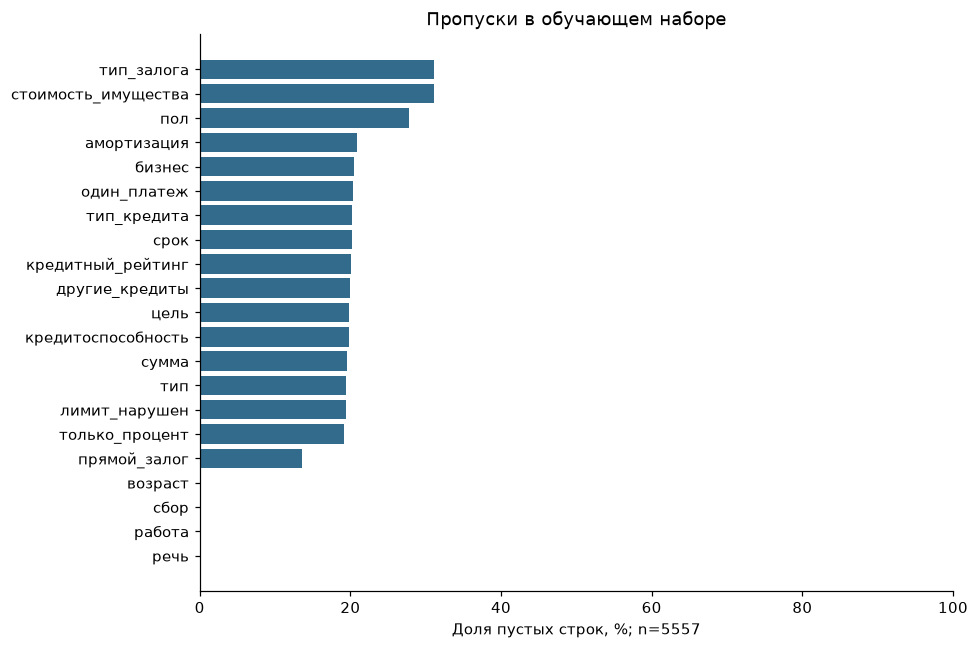

,count,mean,std,min,25%,50%,75%,max
сумма,4471.0,346210.13,188210.26,44765.26,214765.26,314765.26,444765.26,3024765.26
срок,4436.0,341.61,58.11,102.00,366.00,366.00,366.00,366.00
стоимость_имущества,3830.0,526785.76,343350.74,74488.11,304488.11,444488.11,654488.11,4544488.11
кредитный_рейтинг,4443.0,709.63,114.60,511.51,611.01,708.51,809.51,911.51


In [6]:
profile=[]
for c in test.columns:
    a,b=train[c],test[c]
    profile.append({'поле':c,'пропуск_train_%':100*a.eq('').mean(),
                    'пропуск_test_%':100*b.eq('').mean(),'уникальных_train':a.nunique(),
                    'новых_значений_test_строк':int((~b.isin(a)).sum())})
profile=pd.DataFrame(profile)
profile.to_csv(OUT/'data_profile.csv',index=False)
display(profile.round(2))
fig,ax=plt.subplots(figsize=(9,6))
plot=profile[profile['поле'].ne('ID')].sort_values('пропуск_train_%')
ax.barh(plot['поле'],plot['пропуск_train_%'],color='#326B8B')
ax.set(title='Пропуски в обучающем наборе',xlabel='Доля пустых строк, %; n=5557',xlim=(0,100))
save_figure('missingness.png')
numeric_summary=pd.DataFrame({c:pd.to_numeric(train[c],errors='coerce') for c in NUM}).describe().T
display(numeric_summary.round(2))

## 4. Признаки и границы обучения

Сохраняем подход сокомандника: числовые пропуски, неизвестные категории и текст обрабатываются отдельно. Добавляем LTV, запас стоимости залога, число пропусков, длину речи и порядок возрастной группы. LTV рассчитывается только при известном положительном залоге; отношение двух заполненных медиан не выдаём за реальное LTV.

`prepare` делает только построчные преобразования без обучения. Медианы, масштабирование, словарь TF-IDF и One-Hot обучаются в `Pipeline.fit` внутри fold. Для `сбор` сохраняем целую фразу: `not big` нельзя бездумно считать тем же, что `big`. Для речи используем слова и пары слов; стоп-слова и отрицания не удаляем.

In [7]:
def normalize(s):
 s=unicodedata.normalize('NFKC',str(s)).lower().replace('’',"'").replace('‘',"'")
 return re.sub(r'\s+',' ',s).strip().strip('"').strip()

def prepare(raw,engineered=False):
 x=raw.drop(columns=['ID',TARGET],errors='ignore').copy()
 for c in NUM:x[c]=pd.to_numeric(x[c],errors='coerce')
 for c in [c for c in x if c not in NUM]:x[c]=x[c].map(normalize).replace('', 'unknown')
 x['пол']=x['пол'].replace('unknown','n/a')
 if engineered:
  x['ltv']=x['сумма']/x['стоимость_имущества'].where(x['стоимость_имущества']>0)
  x['collateral_buffer']=x['стоимость_имущества']-x['сумма']
  x['missing_count']=raw.drop(columns=['ID',TARGET],errors='ignore').eq('').sum(axis=1)
  x['speech_words']=x['речь'].str.split().str.len()
  x['speech_chars']=x['речь'].str.len()
  x['age_order']=x['возраст'].map({'<25':0,'25-34':1,'35-44':2,'45-54':3,'55-64':4,'65-74':5,'>74':6})
 return x

def make_lr(x,mode,C=4,char=False):
 tab=[c for c in x if c not in TEXT+['speech_words','speech_chars']]
 cols={'fee':['сбор'],'speech':['речь'],'texts':TEXT,'tab':tab,'all':list(x)}[mode]
 nums=[c for c in cols if pd.api.types.is_numeric_dtype(x[c])]
 cats=[c for c in cols if c not in nums and c not in TEXT]
 trans=[]
 if nums:trans.append(('num',Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scaler',StandardScaler())]),nums))
 if cats:trans.append(('cat',OneHotEncoder(handle_unknown='ignore'),cats))
 if 'сбор' in cols:trans.append(('fee',OneHotEncoder(handle_unknown='ignore'),['сбор']))
 if 'речь' in cols:
  trans.append(('word',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True,max_features=30000),'речь'))
  if char:trans.append(('char',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=3,max_features=30000,sublinear_tf=True),'речь'))
 return Pipeline([('features',ColumnTransformer(trans,sparse_threshold=1.0)),('model',LogisticRegression(C=C,max_iter=2000,solver='liblinear',random_state=42))])

def make_cb(x,mode,depth=5,iterations=600):
 cols=[c for c in x if (c not in TEXT+['speech_words','speech_chars'] if mode=='tab' else c not in ['речь','speech_words','speech_chars'] if mode=='fee_tab' else True)]
 cats=[c for c in cols if not pd.api.types.is_numeric_dtype(x[c]) and c!='речь']
 texts=['речь'] if 'речь' in cols else []
 model=CatBoostClassifier(iterations=iterations,depth=depth,learning_rate=.05,l2_leaf_reg=5,loss_function='Logloss',random_seed=42,thread_count=4,verbose=False,allow_writing_files=False,cat_features=cats,text_features=texts)
 return model,cols

def threshold(y,p):
 ts=np.linspace(.10,.9,161); scores=np.array([f1_score(y,p>=t) for t in ts]); best=ts[np.isclose(scores,scores.max())];t=float(best[np.argmin(abs(best-.5))])
 return t,float(scores.max())

def metrics(y,p,t=.5):
 h=p>=t
 return dict(f1=f1_score(y,h),precision=precision_score(y,h,zero_division=0),recall=recall_score(y,h),roc_auc=roc_auc_score(y,p),ap=average_precision_score(y,p),logloss=log_loss(y,p))

In [8]:
X_dev=prepare(dev_raw,engineered=True)
X_hold=prepare(hold_raw,engineered=True)
X_all=prepare(train,engineered=True)
X_test=prepare(test,engineered=True)
assert list(X_all)==list(X_test)
assert 'ID' not in X_all and TARGET not in X_all
speech_groups=X_dev['речь']
print('Повторов нормализованной речи в train:',X_all['речь'].duplicated().sum())
print('Строк test с речью, встреченной в train:',X_test['речь'].isin(X_all['речь']).sum())
fee_stats=pd.DataFrame({'сбор':X_dev['сбор'],'y':y_dev}).groupby('сбор')['y'].agg(['size','mean'])
fee_stats.columns=['клиентов','доля_дефолтов']
fee_stats.to_csv(OUT/'fee_groups_development.csv')
display(fee_stats[fee_stats['клиентов']>=20].sort_values('доля_дефолтов').iloc[np.r_[0:6,-6:0]])
missing_effect=[]
for c in NUM:
    mask=dev_raw[c].eq('').to_numpy()
    for value in [False,True]:
        sub=mask==value
        missing_effect.append({'поле':c,'пропущено':value,'n':sub.sum(),'доля_дефолтов':y_dev[sub].mean()})
display(pd.DataFrame(missing_effect).round(3))
print('Это описательные связи, не доказательство причин дефолта.')

Повторов нормализованной речи в train: 23
Строк test с речью, встреченной в train: 11


,клиентов,доля_дефолтов
сбор,,
popular,47,0.000000
midsized,36,0.000000
midsize,40,0.000000
middling,47,0.000000
middle,48,0.000000
median,29,0.000000
total void,29,0.827586
nothing to show,35,0.828571
zero,30,0.833333


,поле,пропущено,n,доля_дефолтов
0,сумма,False,3568,0.338
1,сумма,True,877,0.352
2,срок,False,3556,0.343
3,срок,True,889,0.331
4,стоимость_имущества,False,3051,0.234
5,стоимость_имущества,True,1394,0.574
6,кредитный_рейтинг,False,3558,0.338
7,кредитный_рейтинг,True,887,0.352


Это описательные связи, не доказательство причин дефолта.


## 4a. Карта слов и рейтинг словосочетаний

Анализируем **только development**: одна строка = один клиент. Повтор слова внутри речи считается один раз. Слова и настоящие последовательности из 2–3 слов отбираются при наличии минимум у 20 клиентов. Для читаемости убраны служебные слова и выражения со служебными краями; отрицания сохранены. Короткие значения `сбор` считаем отдельно целыми фразами.

Нормируем частоту на 100 клиентов каждой группы, поскольку группы разного размера. В таблицах есть и исходные количества. `default_rate_given_term` — доля дефолтов среди клиентов с выражением, а не причинный эффект и не вероятность дефолта нового клиента по одному слову.

**Ранжирование:** сравниваем шансы встретить выражение при дефолте и недефолте. В четырёх ячейках таблицы сопряжённости прибавляем 0.5, чтобы избежать бесконечностей при нуле. `association_score` = log(отношения шансов) / оценка стандартной ошибки. Положительное значение указывает на дефолт, отрицательное — на недефолт. Оценка учитывает поддержку; это исследовательский рейтинг, **не тест статистической значимости после перебора тысяч выражений**.

Размер надписи на облаке — абсолютная сила ассоциации, **не частота и не важность для финальной модели**. Частоту показывает отдельная карта с диагональю равных частот. По рейтингу не изменяем модель после раскрытия holdout.

In [9]:
# Standalone code also embedded verbatim in the competition notebook.
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud

# Compare document presence: one borrower counts once, even if a word is repeated.
MIN_DOCUMENTS = 20
N_DEFAULT = int((y_dev == 1).sum())
N_NONDEFAULT = int((y_dev == 0).sum())
STOP = (set(ENGLISH_STOP_WORDS) | {"i'm","we're","i've","we've","i'll","we'll","it's","that's"}) - {'no','not','nor','never','cannot','without'}

def lexical_statistics(terms, default_counts, nondefault_counts, field):
    a=np.asarray(default_counts,dtype=float)
    b=np.asarray(nondefault_counts,dtype=float)
    c=N_DEFAULT-a;d=N_NONDEFAULT-b
    log_odds=np.log((a+.5)/(c+.5))-np.log((b+.5)/(d+.5))
    standard_error=np.sqrt(1/(a+.5)+1/(b+.5)+1/(c+.5)+1/(d+.5))
    table=pd.DataFrame({'field':field,'term':terms,'n_default':a.astype(int),
        'n_nondefault':b.astype(int),'n_total':(a+b).astype(int),
        'per_100_default':100*a/N_DEFAULT,'per_100_nondefault':100*b/N_NONDEFAULT,
        'difference_pp':100*(a/N_DEFAULT-b/N_NONDEFAULT),
        'default_rate_given_term':a/(a+b),
        'odds_ratio_smoothed':np.exp(log_odds),
        'log_odds':log_odds,'association_score':log_odds/standard_error})
    table['kind']=table.term.str.count(' ').map(lambda n:'word' if n==0 else 'phrase')
    return table[table.n_total>=MIN_DOCUMENTS].copy()

vectorizer=CountVectorizer(ngram_range=(1,3),min_df=MIN_DOCUMENTS,binary=True,
                          token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']*\b")
term_matrix=vectorizer.fit_transform(X_dev['речь'])
a=np.asarray(term_matrix[y_dev==1].sum(axis=0)).ravel()
b=np.asarray(term_matrix[y_dev==0].sum(axis=0)).ravel()
speech_rank=lexical_statistics(vectorizer.get_feature_names_out(),a,b,'речь')
# Drop standalone function words and phrases with function-word edges for readability.
# CountVectorizer built real contiguous n-grams BEFORE filtering; no fake bigrams are formed.
def meaningful(term):
    tokens=term.split()
    return tokens[0] not in STOP and tokens[-1] not in STOP and any(t not in STOP for t in tokens)
speech_rank=speech_rank.loc[speech_rank.term.map(meaningful)].copy()
fee_table=pd.crosstab(X_dev['сбор'],y_dev).reindex(columns=[0,1],fill_value=0)
fee_rank=lexical_statistics(fee_table.index.to_numpy(),fee_table[1].to_numpy(),fee_table[0].to_numpy(),'сбор')
lexical_rank=pd.concat([speech_rank,fee_rank],ignore_index=True)
lexical_rank['associated_class']=np.where(lexical_rank.association_score>=0,'default','nondefault')
lexical_rank['rank_within_field_kind_class']=lexical_rank.groupby(['field','kind','associated_class'])['association_score'].rank(
    ascending=False,method='min')
# Correct nondefault ranking to the most negative score first.
mask=lexical_rank.associated_class.eq('nondefault')
lexical_rank.loc[mask,'rank_within_field_kind_class']=lexical_rank.loc[mask].groupby(['field','kind'])['association_score'].rank(ascending=True,method='min')
lexical_rank.sort_values(['field','kind','associated_class','rank_within_field_kind_class']).to_csv(
    OUT/'word_phrase_rankings.csv',index=False)
view_columns=['term','n_default','n_nondefault','per_100_default','per_100_nondefault',
              'difference_pp','default_rate_given_term','association_score']
for kind in ['word','phrase']:
    part=speech_rank[speech_rank.kind.eq(kind)]
    for side in ['default','nondefault']:
        ordered=part.sort_values('association_score',ascending=side=='nondefault').head(20)
        ordered.to_csv(OUT/f'speech_{kind}_{side}_top20.csv',index=False)
        display(Markdown(f'**Речь: {kind}; связь с {side}**'))
        display(ordered[view_columns].round(3))
display(Markdown('**Сбор: отдельный рейтинг целых значений**'))
display(pd.concat([fee_rank.nsmallest(8,'association_score'),fee_rank.nlargest(8,'association_score')])[view_columns].round(3))
print('База сравнения:',N_DEFAULT,'дефолтов и',N_NONDEFAULT,'недефолтов; min support =',MIN_DOCUMENTS)

**Речь: word; связь с default**

,term,n_default,n_nondefault,per_100_default,per_100_nondefault,difference_pp,default_rate_given_term,association_score
498,bit,738,70,48.745,2.388,46.357,0.913,27.876
2157,not,566,111,37.384,3.787,33.597,0.836,24.641
2646,sure,501,28,33.091,0.955,32.136,0.947,20.002
2730,things,400,104,26.420,3.548,22.872,0.794,19.710
1283,hoping,409,41,27.015,1.399,25.616,0.909,19.498
1271,hope,392,125,25.892,4.265,21.627,0.758,18.962
3013,way,370,95,24.439,3.241,21.197,0.796,18.863
604,challenges,325,93,21.466,3.173,18.293,0.778,17.309
1746,life,406,206,26.816,7.028,19.788,0.663,17.033
888,facing,297,29,19.617,0.989,18.627,0.911,16.221


**Речь: word; связь с nondefault**

,term,n_default,n_nondefault,per_100_default,per_100_nondefault,difference_pp,default_rate_given_term,association_score
1842,looking,140,962,9.247,32.822,-23.575,0.127,-16.145
1062,future,77,832,5.086,28.386,-23.300,0.085,-16.144
863,explore,101,846,6.671,28.864,-22.193,0.107,-15.669
781,eager,26,564,1.717,19.243,-17.525,0.044,-12.877
2222,options,255,1008,16.843,34.391,-17.548,0.202,-12.041
927,financial,652,1821,43.065,62.129,-19.064,0.264,-12.025
836,excited,15,537,0.991,18.321,-17.331,0.027,-11.851
470,believe,22,467,1.453,15.933,-14.480,0.045,-11.600
655,confident,13,520,0.859,17.741,-16.883,0.024,-11.448
731,discuss,208,858,13.738,29.273,-15.535,0.195,-11.229


**Речь: phrase; связь с default**

,term,n_default,n_nondefault,per_100_default,per_100_nondefault,difference_pp,default_rate_given_term,association_score
2161,not sure,482,14,31.836,0.478,31.359,0.972,16.892
898,feeling a bit,182,22,12.021,0.751,11.271,0.892,12.725
502,bit lost,139,12,9.181,0.409,8.772,0.921,10.655
891,facing some financial,138,10,9.115,0.341,8.774,0.932,10.356
902,feels like,121,12,7.992,0.409,7.583,0.910,10.086
1581,income is low,160,94,10.568,3.207,7.361,0.630,9.485
1753,life has thrown,108,8,7.133,0.273,6.860,0.931,9.166
686,currently facing,93,9,6.143,0.307,5.836,0.912,8.792
1886,make ends meet,108,49,7.133,1.672,5.462,0.688,8.606
1885,make ends,108,49,7.133,1.672,5.462,0.688,8.606


**Речь: phrase; связь с nondefault**

,term,n_default,n_nondefault,per_100_default,per_100_nondefault,difference_pp,default_rate_given_term,association_score
1800,loan options,57,414,3.765,14.125,-10.360,0.121,-9.886
1256,high income,153,653,10.106,22.279,-12.173,0.190,-9.725
1847,looking forward,6,264,0.396,9.007,-8.611,0.022,-7.873
869,explore loan,15,224,0.991,7.642,-6.652,0.063,-7.869
1840,look forward,4,279,0.264,9.519,-9.255,0.014,-7.487
870,explore loan options,15,205,0.991,6.994,-6.003,0.068,-7.487
784,eager to explore,5,198,0.330,6.755,-6.425,0.025,-6.903
1855,looking to secure,10,169,0.661,5.766,-5.105,0.056,-6.801
945,financial goals,3,225,0.198,7.677,-7.478,0.013,-6.640
651,committed to repaying,4,179,0.264,6.107,-5.843,0.022,-6.451


**Сбор: отдельный рейтинг целых значений**

,term,n_default,n_nondefault,per_100_default,per_100_nondefault,difference_pp,default_rate_given_term,association_score
28,commonplace,1,43,0.066,1.467,-1.401,0.023,-3.274
377,usual,1,41,0.066,1.399,-1.333,0.024,-3.214
351,standard,1,33,0.066,1.126,-1.060,0.029,-2.941
327,routine,0,56,0.000,1.911,-1.911,0.000,-2.876
27,common,0,52,0.000,1.774,-1.774,0.000,-2.822
110,middle,0,48,0.000,1.638,-1.638,0.000,-2.765
111,middling,0,47,0.000,1.604,-1.604,0.000,-2.749
316,popular,0,47,0.000,1.604,-1.604,0.000,-2.749
341,skimpiness,31,7,2.048,0.239,1.809,0.816,5.187
49,empty space,32,10,2.114,0.341,1.772,0.762,5.074


База сравнения: 1514 дефолтов и 2931 недефолтов; min support = 20


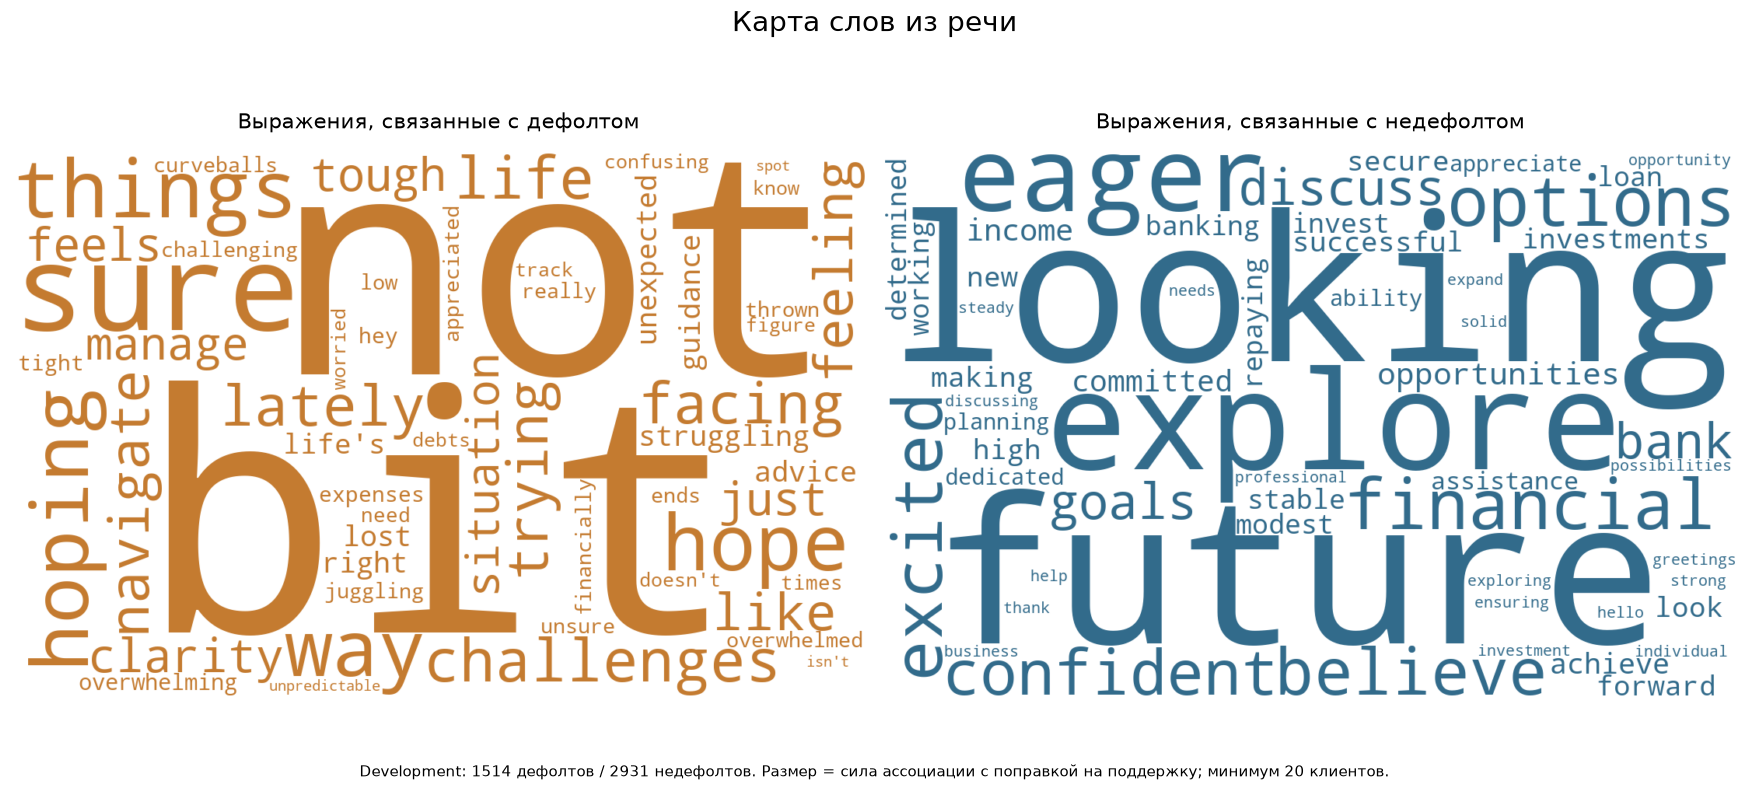

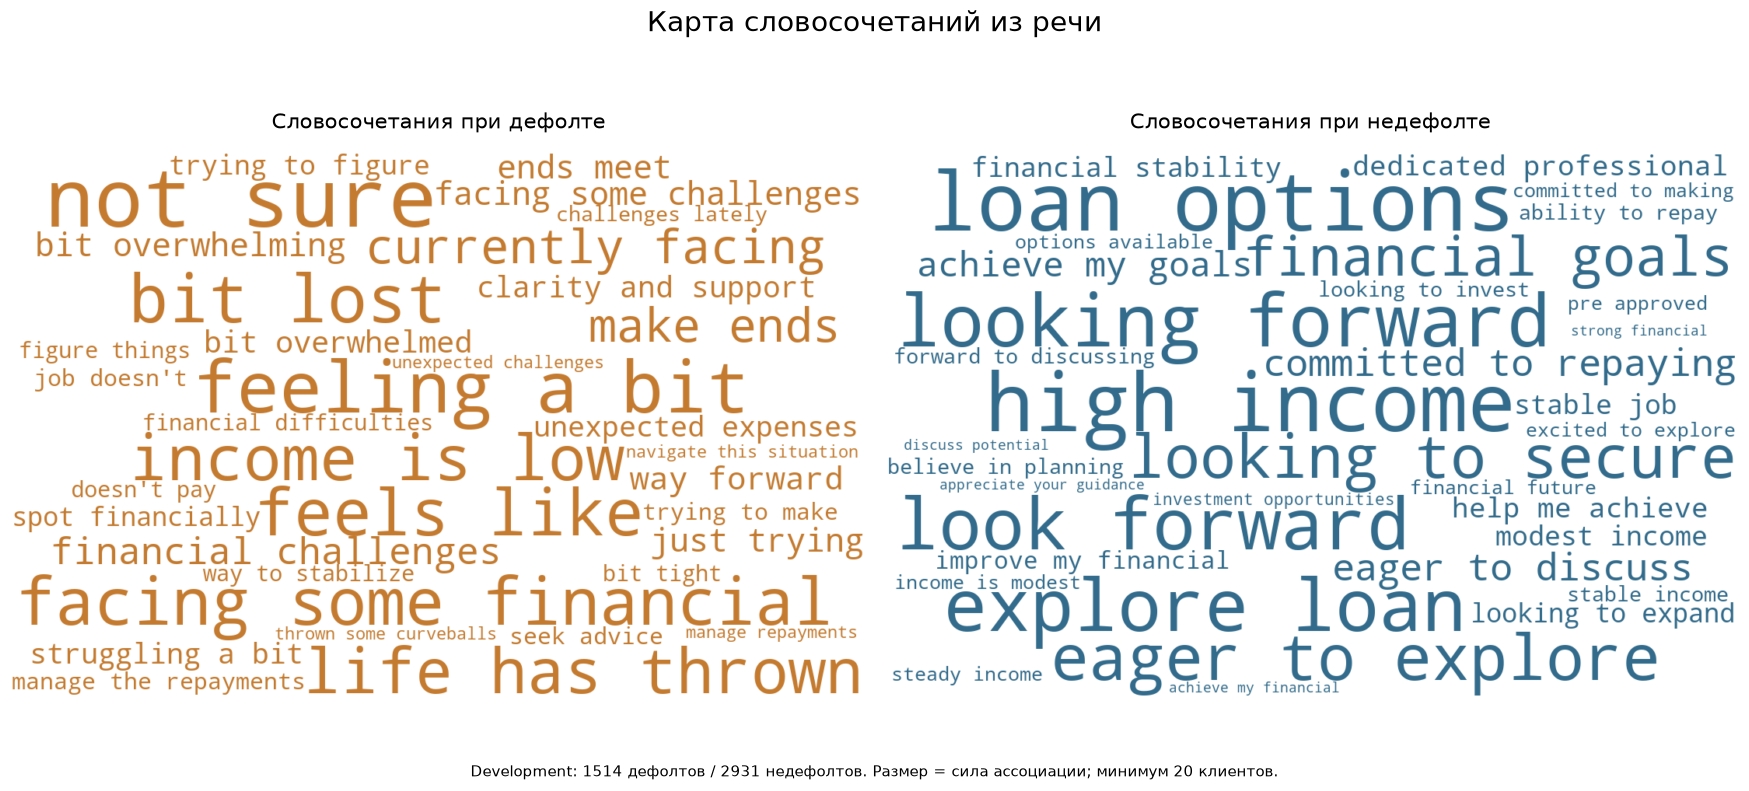

In [10]:
# Chart contract: two clouds; term size = |association_score|, NOT prevalence or causal importance.
# Two roots only; exact counts and denominators remain in ranking tables.
fig,axes=plt.subplots(1,2,figsize=(16,7))
for ax,side,color,title in [(axes[0],1,'#C47B30','Выражения, связанные с дефолтом'),
                           (axes[1],-1,'#326B8B','Выражения, связанные с недефолтом')]:
    part=speech_rank[(speech_rank.association_score*side>0)&speech_rank.kind.eq('word')].copy()
    part['weight']=part.association_score.abs()
    part=part.sort_values('weight',ascending=False)
    chosen={}
    # Avoid putting the same signal into the cloud as both a phrase and its nested fragment.
    for row in part.itertuples():
        if any((' '+row.term+' ') in (' '+old+' ') or (' '+old+' ') in (' '+row.term+' ') for old in chosen):
            continue
        chosen[row.term]=row.weight
        if len(chosen)==55:break
    cloud=WordCloud(width=1100,height=700,background_color='white',max_words=55,
                    prefer_horizontal=.95,random_state=42,collocations=False,
                    color_func=lambda *args,c=color,**kwargs:c).generate_from_frequencies(chosen)
    ax.imshow(cloud,interpolation='bilinear');ax.axis('off');ax.set_title(title,fontsize=14,pad=16)
fig.suptitle('Карта слов из речи',fontsize=18,y=1.01)
fig.text(.5,.015,f'Development: {N_DEFAULT} дефолтов / {N_NONDEFAULT} недефолтов. Размер = сила ассоциации с поправкой на поддержку; минимум {MIN_DOCUMENTS} клиентов.',ha='center',fontsize=10)
save_figure('word_map.png')

# Separate phrase cloud: preserves negation and contiguous 2-3 token context.
fig,axes=plt.subplots(1,2,figsize=(16,7))
for ax,side,color,title in [(axes[0],1,'#C47B30','Словосочетания при дефолте'),
                           (axes[1],-1,'#326B8B','Словосочетания при недефолте')]:
    part=speech_rank[(speech_rank.association_score*side>0)&speech_rank.kind.eq('phrase')].copy()
    part['weight']=part.association_score.abs()
    chosen={}
    for row in part.sort_values('weight',ascending=False).itertuples():
        if any((' '+row.term+' ') in (' '+old+' ') or (' '+old+' ') in (' '+row.term+' ') for old in chosen):
            continue
        chosen[row.term]=row.weight
        if len(chosen)==35:break
    cloud=WordCloud(width=1100,height=700,background_color='white',max_words=35,
                    max_font_size=105,min_font_size=15,prefer_horizontal=1.,random_state=42,
                    collocations=False,color_func=lambda *args,c=color,**kwargs:c).generate_from_frequencies(chosen)
    ax.imshow(cloud,interpolation='bilinear');ax.axis('off');ax.set_title(title,fontsize=14,pad=16)
fig.suptitle('Карта словосочетаний из речи',fontsize=18,y=1.01)
fig.text(.5,.015,f'Development: {N_DEFAULT} дефолтов / {N_NONDEFAULT} недефолтов. Размер = сила ассоциации; минимум {MIN_DOCUMENTS} клиентов.',ha='center',fontsize=10)
save_figure('phrase_map.png')

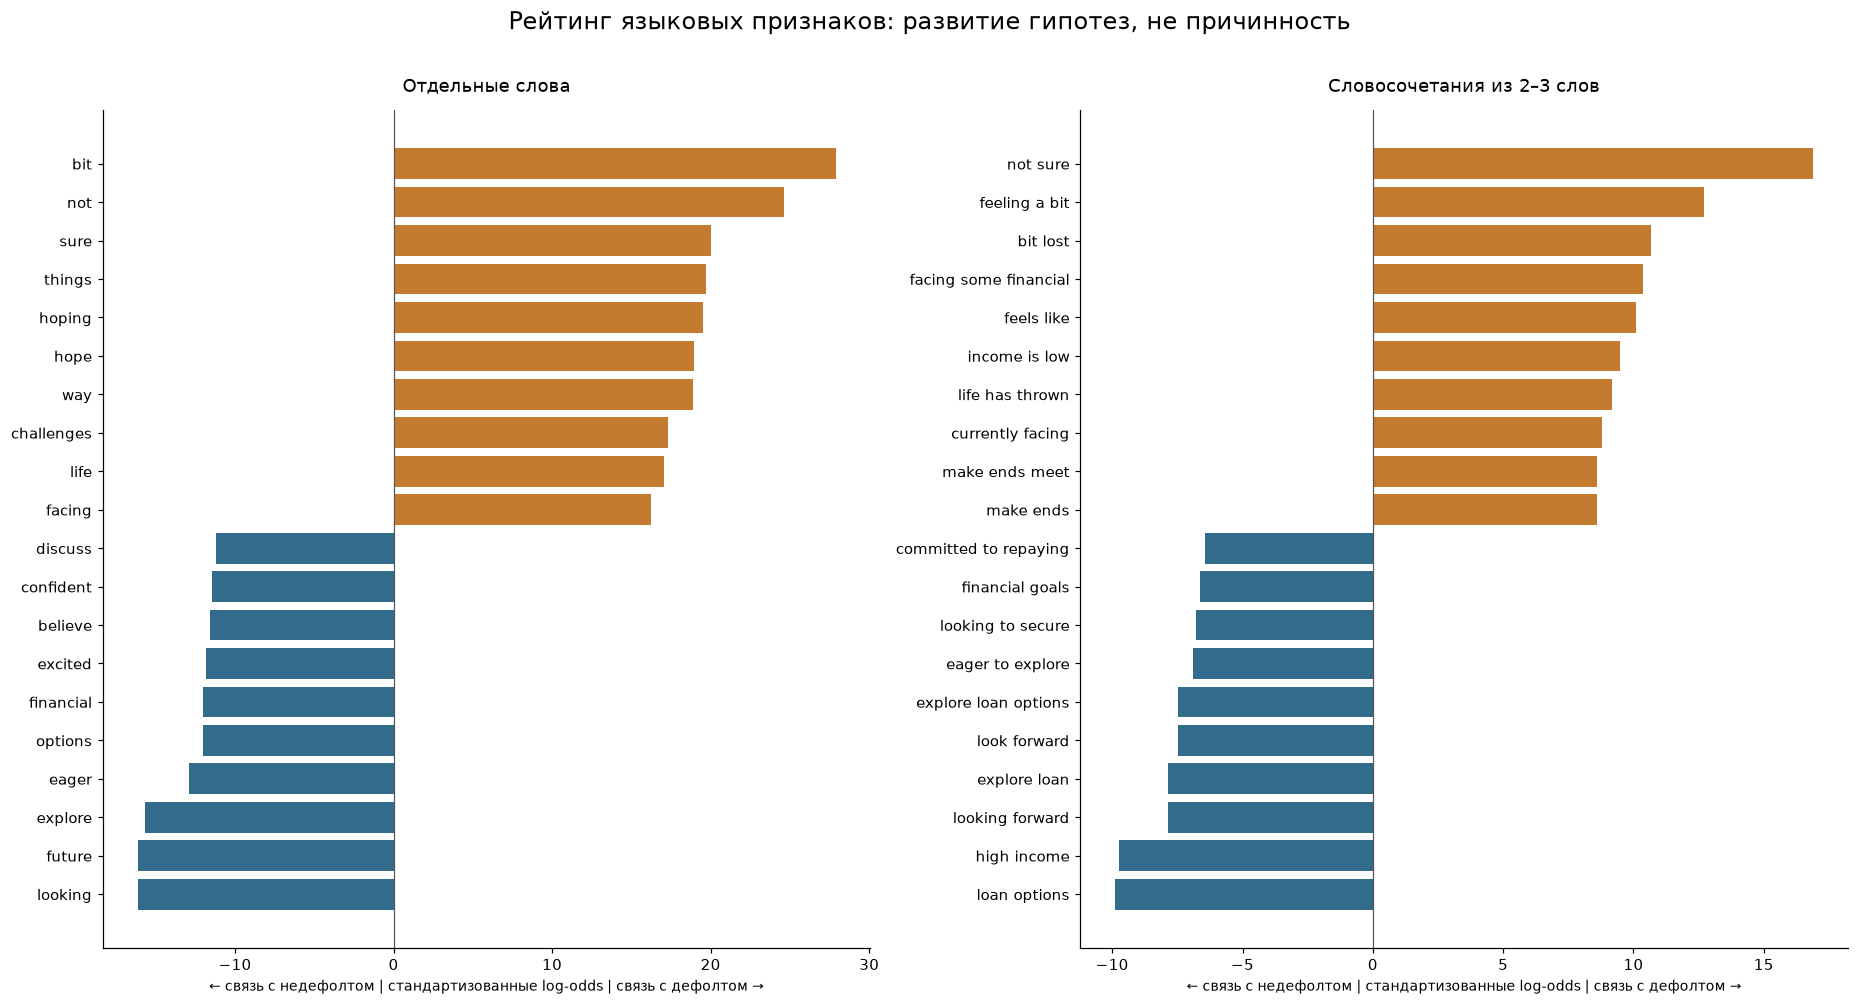

In [11]:
# Ranked diverging bars: sorted signed association scores, separate words / phrases.
fig,axes=plt.subplots(1,2,figsize=(17,9))
for ax,kind,title in [(axes[0],'word','Отдельные слова'),(axes[1],'phrase','Словосочетания из 2–3 слов')]:
    part=speech_rank[speech_rank.kind.eq(kind)]
    top=pd.concat([part.nsmallest(10,'association_score'),part.nlargest(10,'association_score')]).sort_values('association_score')
    colors=np.where(top.association_score>0,'#C47B30','#326B8B')
    ax.barh(top.term,top.association_score,color=colors)
    ax.axvline(0,color='#555555',linewidth=.8)
    ax.set_title(title,pad=12)
    ax.set_xlabel('← связь с недефолтом | стандартизованные log-odds | связь с дефолтом →',fontsize=9)
fig.suptitle('Рейтинг языковых признаков: развитие гипотез, не причинность',fontsize=16,y=1.01)
save_figure('word_phrase_ranking.png')

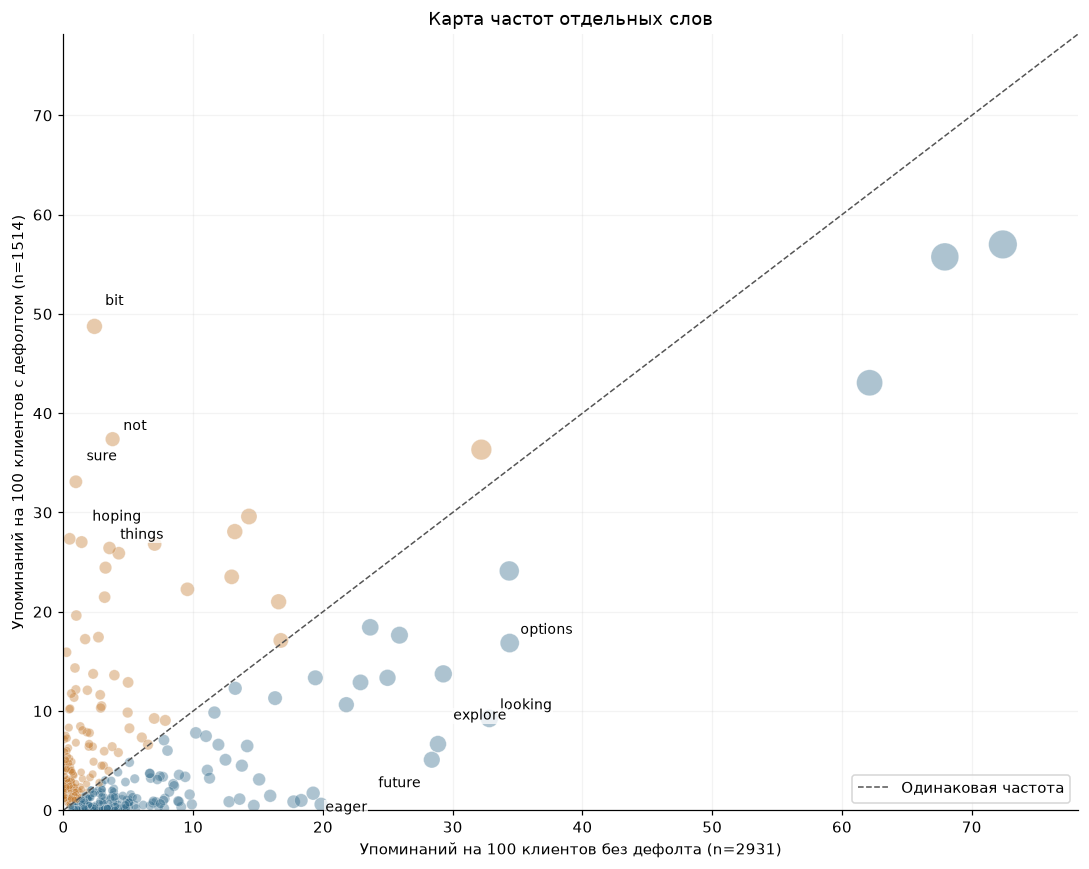

In [12]:
# A frequency map makes the absolute prevalence visible, including words common in both classes.
# Labels limited to 12 salient non-overlapping phrases to keep the map readable.
part=speech_rank[speech_rank.kind.eq('word')].copy()
fig,ax=plt.subplots(figsize=(10,8))
colors=np.where(part.association_score>=0,'#C47B30','#326B8B')
ax.scatter(part.per_100_nondefault,part.per_100_default,s=15+part.n_total/9,
           c=colors,alpha=.4,edgecolors='white',linewidth=.4)
limit=max(part.per_100_nondefault.max(),part.per_100_default.max())*1.08
ax.plot([0,limit],[0,limit],'--',color='#555555',linewidth=1,label='Одинаковая частота')
# Annotate the extremes; rank chart provides exact readable names for dense areas.
annot=pd.concat([part.nsmallest(5,'association_score'),part.nlargest(5,'association_score')])
for k,row in enumerate(annot.itertuples()):
    ax.annotate(row.term,(row.per_100_nondefault,row.per_100_default),
                xytext={'future':(-35,-18),'explore':(10,16),'eager':(8,-12)}.get(row.term,(7,6+(k%2)*8)),
                textcoords='offset points',fontsize=9,bbox=dict(facecolor='white',edgecolor='none',alpha=.75,pad=.6))
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel=f'Упоминаний на 100 клиентов без дефолта (n={N_NONDEFAULT})',
       ylabel=f'Упоминаний на 100 клиентов с дефолтом (n={N_DEFAULT})',title='Карта частот отдельных слов')
ax.legend(loc='lower right');ax.grid(alpha=.15)
save_figure('word_frequency_map.png')

### Почему высокое качество требует проверки

Словесные значения `сбор` имеют очень разные частоты дефолта. Речь содержит устойчивые формулировки финансовых трудностей или уверенности. Это мотивирует текстовые модели и их сочетание, но не доказывает доступность таких сигналов в реальном процессе.

Проверяем гипотезу абляциями: только анкета; только `сбор`; только речь; оба текста; добавление анкеты и новых признаков. Повторяющиеся речи отдельно группируем при стресс-проверке. По скрытым ответам test или таблице лидеров ничего не подбираем.

## 5. Модели: от простых ориентиров к стекингу

- **Логистическая регрессия:** простой воспроизводимый baseline для разреженного текста.
- **CatBoost:** нелинейные взаимодействия чисел и категорий; отдельный вариант с его собственным текстовым механизмом проверен в исследовательском журнале.
- **Стекинг:** сначала TF-IDF + логистическая регрессия превращают речь в оценку риска. Затем CatBoost объединяет её с `сбор` и анкетой.

Ключевой момент: метамодель обучается на **внутренних OOF-прогнозах речи**, а не на предсказаниях текстовой модели по собственному обучению. Для нового клиента усредняются четыре внутренние текстовые модели. Этот внутренний цикл заново запускается в каждом внешнем fold.

Из прошлого решения сохраняем сравнение семейств признаков. Статистический рейтинг сам по себе не доказывает пользу отбора: отдельно проверяем L1-отбор внутри каждого fold.

In [13]:
class TextStack(ClassifierMixin,BaseEstimator):
 def __init__(self,C=4.,depth=4,iterations=500,mode='all',seed=42):self.C=C;self.depth=depth;self.iterations=iterations;self.mode=mode;self.seed=seed
 def fit(self,X,y):
  X=X.reset_index(drop=True);y=np.asarray(y);self.classes_=np.array([0,1]);p=np.zeros(len(y));self.text_models_=[]
  for a,b in StratifiedKFold(4,shuffle=True,random_state=self.seed).split(X,y):
   m=make_lr(X,'speech',self.C);m.fit(X.iloc[a],y[a]);p[b]=m.predict_proba(X.iloc[b])[:,1];self.text_models_.append(m)
  z=self.meta_features(X,p);cats=[c for c in z if not pd.api.types.is_numeric_dtype(z[c])]
  self.meta_=CatBoostClassifier(depth=self.depth,iterations=self.iterations,learning_rate=.04,l2_leaf_reg=7,random_seed=self.seed,verbose=False,thread_count=4,allow_writing_files=False,cat_features=cats)
  self.meta_.fit(z,y);return self
 def meta_features(self,X,p):
  if self.mode=='texts':z=X[['сбор']].copy()
  else:z=X.drop(columns=['речь']).copy()
  if self.mode=='no_demographics':z=z.drop(columns=['пол','возраст','age_order'],errors='ignore')
  z['speech_probability']=p;z['speech_logit']=logit(np.clip(p,1e-6,1-1e-6))
  return z
 def predict_proba(self,X):
  p=np.mean([m.predict_proba(X)[:,1] for m in self.text_models_],axis=0)
  return self.meta_.predict_proba(self.meta_features(X,p))

In [14]:
class FeeSpeechModel(ClassifierMixin,BaseEstimator):
 def __init__(self,C=4.0,strategy='bayes',alpha=.5):self.C=C;self.strategy=strategy;self.alpha=alpha
 def fit(self,X,y):
  self.classes_=np.array([0,1]);self.prior_=float(np.mean(y))
  stats=pd.DataFrame({'fee':X['сбор'].to_numpy(),'y':y}).groupby('fee')['y'].agg(['sum','count'])
  self.fee_risk_=((stats['sum']+self.alpha*self.prior_)/(stats['count']+self.alpha)).to_dict()
  self.speech_=make_lr(X,'speech',self.C,False)
  if self.strategy=='conditional':
   mask=X['сбор'].map(self.fee_risk_).to_numpy()>.2
   self.speech_.fit(X.loc[mask],np.asarray(y)[mask])
  else:self.speech_.fit(X,y)
  return self
 def predict_proba(self,X):
  p=self.speech_.predict_proba(X)[:,1];q=X['сбор'].map(self.fee_risk_).fillna(self.prior_).to_numpy()
  if self.strategy=='bayes':p=expit(logit(np.clip(p,1e-6,1-1e-6))+logit(np.clip(q,1e-6,1-1e-6))-logit(self.prior_))
  elif self.strategy=='conditional':p=np.where(q>.2,p,q)
  elif self.strategy=='gate':p=np.where(q>.2,p,p*q)
  return np.c_[1-p,p]

In [15]:
class FrameCatBoost(ClassifierMixin,BaseEstimator):
    def __init__(self,mode='tab',depth=5,iterations=600):
        self.mode=mode;self.depth=depth;self.iterations=iterations
    def fit(self,X,y):
        self.model_,self.columns_=make_cb(X,self.mode,self.depth,self.iterations)
        self.model_.fit(X[self.columns_],y)
        self.classes_=np.array([0,1]);return self
    def predict_proba(self,X):return self.model_.predict_proba(X[self.columns_])

class AverageModel(ClassifierMixin,BaseEstimator):
    def __init__(self,models):self.models=models
    def fit(self,X,y):
        self.classes_=np.array([0,1])
        for m,w in self.models:m.fit(X,y)
        return self
    def predict_proba(self,X):return sum(w*m.predict_proba(X) for m,w in self.models)

def make_selected(x):
    m=make_lr(x,'texts',4)
    return Pipeline([('features',m.named_steps['features']),
                     ('select',SelectFromModel(LinearSVC(C=.15,penalty='l1',dual=False,
                                                        random_state=42,max_iter=5000))),
                     ('model',LogisticRegression(C=4,solver='liblinear',max_iter=2000,random_state=42))])

def factory(name,x):
    if name=='LR tab':return make_lr(x,'tab',1)
    if name=='LR fee':return make_lr(x,'fee',4)
    if name=='LR speech':return make_lr(x,'speech',4)
    if name=='LR texts':return make_lr(x,'texts',4)
    if name=='LR all':return make_lr(x,'all',4)
    if name=='LR texts L1 selection':return make_selected(x)
    if name=='CatBoost tab':return FrameCatBoost('tab')
    if name=='Fee + speech Bayes':return FeeSpeechModel(4.,'bayes')
    if name=='Stack texts':return TextStack(mode='texts',depth=3)
    if name=='Stack all d3':return TextStack(mode='all',depth=3)
    if name=='Stack all d5':return TextStack(mode='all',depth=5)
    if name=='Stack no demographics':return TextStack(mode='no_demographics',depth=3)
    if name=='Blend stacks 50/50':return AverageModel([(TextStack(depth=3),.5),(TextStack(depth=5),.5)])
    if name=='Blend stacks 75/25':return AverageModel([(TextStack(depth=3),.75),(TextStack(depth=5),.25)])
    if name=='Blend stack Bayes 50/50':return AverageModel([(TextStack(depth=3),.5),(FeeSpeechModel(4.,'bayes'),.5)])
    if name=='Blend stack Bayes 75/25':return AverageModel([(TextStack(depth=3),.75),(FeeSpeechModel(4.,'bayes'),.25)])
    raise ValueError(name)

def cv_predictions(name,x,y,folds):
    p=np.full(len(y),np.nan);fold_rows=[]
    for k,(a,b) in enumerate(folds):
        model=factory(name,x)
        model.fit(x.iloc[a],y[a])
        p[b]=model.predict_proba(x.iloc[b])[:,1]
        fold_rows.append({'model':name,'fold':k,'n':len(b),'f1_05':f1_score(y[b],p[b]>=.5)})
    assert np.isfinite(p).all()
    return p,fold_rows

## 6. Сравнение на общих пяти folds

F1 для класса `дефолт=1`: $2TP/(2TP+FP+FN)$. F1 не учитывает размер кредита и доход, поэтому отдельно нужен денежный расчёт.

Колонка `f1_05` использует стандартный порог 0.5. `f1_tuned_development` использует лучший порог на development OOF: это **результат подбора**, немного оптимистичный. При равенстве выбираем порог ближе к 0.5. Количество вариантов и результаты сохраняем, не скрываем неудачный отбор.

In [16]:
folds=list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(X_dev,y_dev))
NAMES=['LR tab','LR fee','LR speech','LR texts','LR all','LR texts L1 selection',
       'CatBoost tab','Fee + speech Bayes','Stack texts','Stack all d3','Stack all d5',
       'Stack no demographics']
oof={};rows=[];fold_log=[]
for name in NAMES:
    start=time.time()
    p,fr=cv_predictions(name,X_dev,y_dev,folds)
    oof[name]=p;fold_log.extend(fr)
    t,best=threshold(y_dev,p)
    row={'model':name,'f1_05':f1_score(y_dev,p>=.5),'threshold':t,
         'f1_tuned_development':best,'fold_sd_05':np.std([r['f1_05'] for r in fr]),
         'seconds':time.time()-start,'AP':average_precision_score(y_dev,p),
         'logloss':log_loss(y_dev,p)}
    rows.append(row)
    print(name,round(row['f1_05'],5),'tuned',round(best,5),flush=True)
# Небольшой заранее заданный набор ансамблей, без поиска тысяч весов.
for name,a,b,w in [('Blend stacks 50/50','Stack all d3','Stack all d5',.5),
                   ('Blend stacks 75/25','Stack all d3','Stack all d5',.75),
                   ('Blend stack Bayes 50/50','Stack all d3','Fee + speech Bayes',.5),
                   ('Blend stack Bayes 75/25','Stack all d3','Fee + speech Bayes',.75)]:
    p=w*oof[a]+(1-w)*oof[b];oof[name]=p;t,best=threshold(y_dev,p)
    rows.append({'model':name,'f1_05':f1_score(y_dev,p>=.5),'threshold':t,
                 'f1_tuned_development':best,'AP':average_precision_score(y_dev,p),'logloss':log_loss(y_dev,p)})
comparison=pd.DataFrame(rows).sort_values('f1_tuned_development',ascending=False)
comparison.to_csv(OUT/'model_comparison.csv',index=False)
pd.DataFrame(fold_log).to_csv(OUT/'fold_scores.csv',index=False)
pd.DataFrame({'ID':dev_raw.ID, 'y':y_dev, **oof}).to_csv(OUT/'development_oof.csv',index=False)
display(comparison.round(5))

LR tab 0.57721 tuned 0.61459


LR fee 0.81936 tuned 0.82694


LR speech 0.9418 tuned 0.94563


LR texts 0.968 tuned 0.97103


LR all 0.96439 tuned 0.967


LR texts L1 selection 0.95408 tuned 0.95437


... (3 outputs left out)

Stack all d3 0.97973 tuned 0.98008


Stack all d5 0.97937 tuned 0.98043


Stack no demographics 0.97942 tuned 0.98011


,model,f1_05,threshold,f1_tuned_development,fold_sd_05,seconds,AP,logloss
10,Stack all d5,0.97937,0.385,0.98043,0.00608,13.09597,0.99365,0.05441
12,Blend stacks 50/50,0.98005,0.420,0.98042,NaN,NaN,0.99362,0.05461
11,Stack no demographics,0.97942,0.365,0.98011,0.00585,9.58072,0.99394,0.05438
13,Blend stacks 75/25,0.97973,0.365,0.98011,NaN,NaN,0.99361,0.05482
15,Blend stack Bayes 75/25,0.97940,0.430,0.98011,NaN,NaN,0.99370,0.05722
9,Stack all d3,0.97973,0.415,0.98008,0.00588,9.07309,0.99357,0.05512
14,Blend stack Bayes 50/50,0.97840,0.495,0.97874,NaN,NaN,0.99338,0.06175
8,Stack texts,0.97409,0.670,0.97564,0.00576,5.90742,0.99082,0.06317
7,Fee + speech Bayes,0.97128,0.655,0.97472,0.00648,0.89948,0.99148,0.07654
3,LR texts,0.96800,0.595,0.97103,0.00959,0.93721,0.98827,0.09742


### 6a. Автоматическое извлечение: проверка трёхсловных выражений

Словарь **не задаётся вручную**. `TfidfVectorizer.fit` сам находит слова и пары токенов в обучающей части каждого fold, фильтрует слишком редкие варианты (`min_df=2`) и вычисляет IDF. Логистическая регрессия учит веса этих признаков по ответам. При `transform` нового текста используется только выученный словарь. Финальный CatBoost получает прогноз текстовой модели вместе с анкетой.

Рейтинги из секции 4a служат объяснению и не копируются в модель как готовый словарь. Иначе можно случайно использовать ответы внешнего fold при отборе фраз.

Дополнительная проверка по запросу: слова + пары + тройки токенов, включая односимвольные слова (`a`, `I`) в контекст. У базового TF-IDF стандартная токенизация пропускает односимвольные слова: поэтому его пары токенов иногда соответствуют фразам из трёх исходных слов. Новый вариант одновременно проверяет расширенный контекст и более буквальную токенизацию. Результаты относятся только к development. Контрольную выборку при этом сравнении не используем. До расчёта установили минимальный прирост для замены 0.002 F1; в проведённом эксперименте прирост отрицательный, базовая конфигурация остаётся прежней.

In [17]:
class TextStackTrigrams(TextStack):
    def fit(self,X,y):
        X=X.reset_index(drop=True);y=np.asarray(y)
        self.classes_=np.array([0,1]);p=np.zeros(len(y));self.text_models_=[]
        for a,b in StratifiedKFold(4,shuffle=True,random_state=self.seed).split(X,y):
            model=make_lr(X,'speech',self.C)
            model.named_steps['features'].transformers=[
                ('word',TfidfVectorizer(ngram_range=(1,3),min_df=2,sublinear_tf=True,
                    max_features=30000,token_pattern=r"(?u)\b\w+\b"),'речь')]
            model.fit(X.iloc[a],y[a]);p[b]=model.predict_proba(X.iloc[b])[:,1]
            self.text_models_.append(model)
        z=self.meta_features(X,p)
        cats=[c for c in z if not pd.api.types.is_numeric_dtype(z[c])]
        self.meta_=CatBoostClassifier(depth=self.depth,iterations=self.iterations,
            learning_rate=.04,l2_leaf_reg=7,random_seed=self.seed,verbose=False,
            thread_count=4,allow_writing_files=False,cat_features=cats)
        self.meta_.fit(z,y);return self

trigram_oof=np.zeros(len(y_dev))
for a,b in folds:
    model=TextStackTrigrams(depth=5).fit(X_dev.iloc[a],y_dev[a])
    trigram_oof[b]=model.predict_proba(X_dev.iloc[b])[:,1]
trigram_threshold,trigram_f1=threshold(y_dev,trigram_oof)
base_threshold,base_f1=threshold(y_dev,oof['Stack all d5'])
phrase_experiment=pd.DataFrame([
    {'variant':'Automatic words + token pairs','OOF_F1_tuned':base_f1,'threshold':base_threshold},
    {'variant':'Automatic 1-3 grams + single-letter tokens','OOF_F1_tuned':trigram_f1,'threshold':trigram_threshold}])
phrase_experiment.to_csv(OUT/'automatic_phrase_experiment.csv',index=False)
display(phrase_experiment)
print('Изменение F1:',trigram_f1-base_f1)
print('Проверенная финальная конфигурация остаётся Stack all d5 со словами и парами токенов.')

,variant,OOF_F1_tuned,threshold
0,Automatic words + token pairs,0.980431,0.385
1,Automatic 1-3 grams + single-letter tokens,0.978117,0.320


Изменение F1: -0.0023144665707712786
Проверенная финальная конфигурация остаётся Stack all d5 со словами и парами токенов.


### Зафиксированная конфигурация

Конфигурация ниже выбрана после исследовательских экспериментов только на development и до раскрытия holdout. При повторном запуске имя не заменяется по результату holdout. Порог пересчитывается на тех же development OOF. Все необходимые сравнения и расширенный поиск находятся ниже в этом же ноутбуке.

Не выбираем модель только по минимальной разнице в четвёртом знаке F1: проверяем разброс по folds, альтернативное разбиение, сложность и калибровку.

Зафиксировано: Stack all d5 порог: 0.385


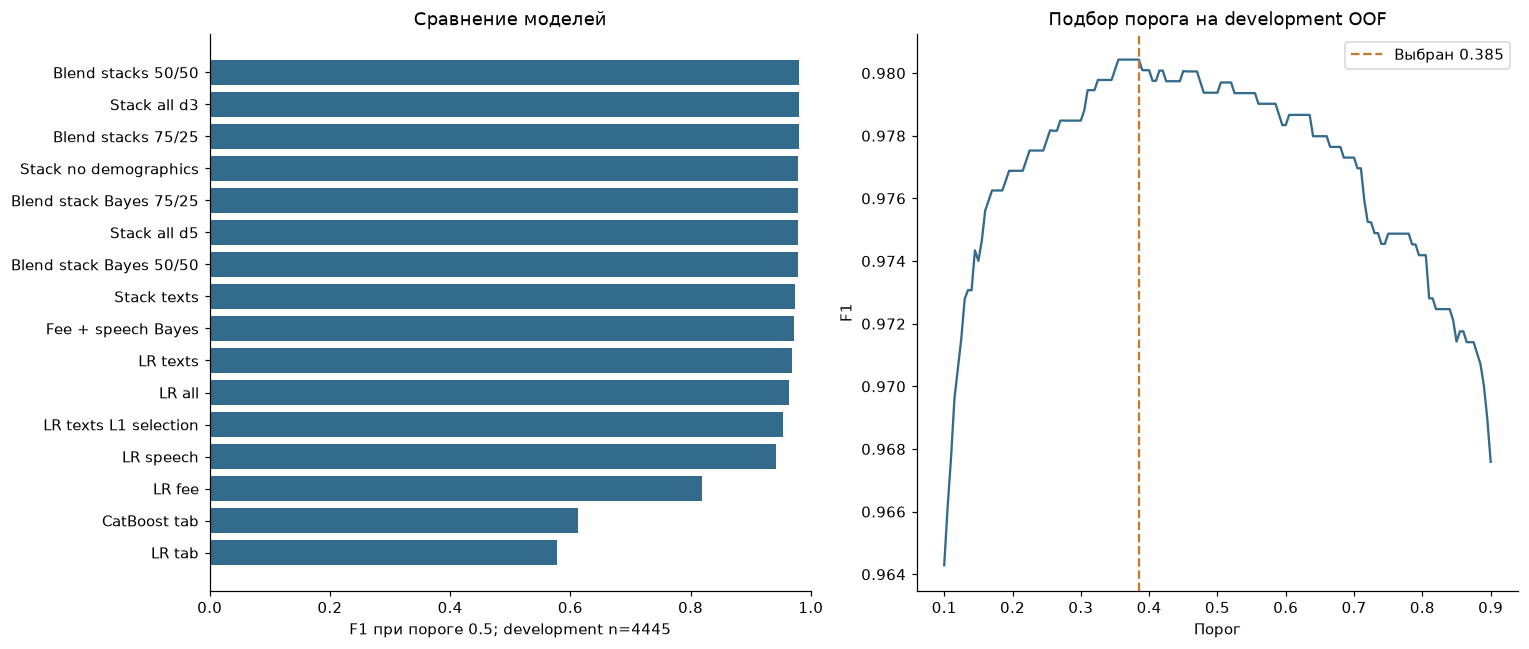

In [18]:
SELECTED = 'Stack all d5'
selected_row=comparison.set_index('model').loc[SELECTED]
F1_THRESHOLD=float(selected_row['threshold'])
selected_oof=oof[SELECTED]
print('Зафиксировано:',SELECTED,'порог:',F1_THRESHOLD)
(OUT/'selection.json').write_text(json.dumps({'model':SELECTED,'threshold':F1_THRESHOLD,
    'holdout_seed':HOLDOUT_SEED,'selection_scope':'development only'},ensure_ascii=False,indent=2))
fig,axes=plt.subplots(1,2,figsize=(14,6))
plot=comparison.sort_values('f1_05')
axes[0].barh(plot['model'],plot['f1_05'],color='#326B8B')
axes[0].set(xlim=(0,1),xlabel='F1 при пороге 0.5; development n=4445',title='Сравнение моделей')
ts=np.linspace(.1,.9,161)
axes[1].plot(ts,[f1_score(y_dev,selected_oof>=t) for t in ts],color='#326B8B')
axes[1].axvline(F1_THRESHOLD,color='#C47B30',linestyle='--',label=f'Выбран {F1_THRESHOLD:.3f}')
axes[1].set(xlabel='Порог',ylabel='F1',title='Подбор порога на development OOF')
axes[1].legend()
save_figure('models_threshold.png')

## 7. Проверка устойчивости на development

Повторяем внешний CV с другим seed. Затем помещаем одинаковые нормализованные речи целиком в один fold (`StratifiedGroupKFold`). Это проверяет точные повторы, но не все смысловые перефразировки. Порог не подстраиваем к каждой проверке. Результаты всё ещё относятся к development, а не к независимому внешнему банку.

In [19]:
stress=[]
for label,splitter in [
    ('Другой seed',list(StratifiedKFold(5,shuffle=True,random_state=137).split(X_dev,y_dev))),
    ('Группы одинаковой речи',list(StratifiedGroupKFold(5,shuffle=True,random_state=42).split(X_dev,y_dev,groups=X_dev['речь'])))]:
    if label.startswith('Группы'):
        for a,b in splitter: assert not(set(X_dev.iloc[a]['речь'])&set(X_dev.iloc[b]['речь']))
    p,_=cv_predictions(SELECTED,X_dev,y_dev,splitter)
    stress.append({'проверка':label,'F1':f1_score(y_dev,p>=F1_THRESHOLD),
                   'precision':precision_score(y_dev,p>=F1_THRESHOLD),
                   'recall':recall_score(y_dev,p>=F1_THRESHOLD)})
stress=pd.DataFrame(stress)
stress.to_csv(OUT/'robustness.csv',index=False)
display(stress)

,проверка,F1,precision,recall
0,Другой seed,0.978723,0.985274,0.972259
1,Группы одинаковой речи,0.979104,0.983344,0.974901


## 8. Расширенный поиск: стекинг, автофразы и смеси

Далее полностью пересчитываем дополнительный эксперимент. Он использует то же разбиение development,
те же функции подготовки и те же исходные CSV. Результаты пишутся в `ensembles/`, чтобы отделить
дополнительных кандидатов от основной отправки. Все функции встроены в этот ноутбук; кэш не загружается.

### Протокол подбора

Внешние 5 фолдов: только оценка. Внутренние 3 фолда: сравнение конфигураций, порогов и смесей.
Ещё 4 фолда внутри каждого стекинга дают OOF-прогноз речи для обучения метамодели CatBoost.
Словари, TF-IDF, заполнение пропусков и supervised-отбор фраз обучаются заново на своей
обучающей части. Внешние ответы не участвуют ни в подборе, ни в early stopping.

Проверяем C логистической регрессии 1, 4, 16; глубину CatBoost 3/5; 400/500/700 деревьев;
L2 5/7/10; learning rate 0.035/0.04/0.05. Это **шесть совместных наборов параметров**, каждый
без/с дополнительными фразами, а не полный декартов перебор. Текстовая часть использует
автоматические униграммы/биграммы во всех стекингах, включая варианты «без дополнительных фраз».

Сравниваем отдельный стек, лучший стек с фразами, среднее двух стеков, смеси обычного и
обогащённого стеков 50/50 и 25/75, смеси стека с LR 90/10 и 75/25. При разнице меньше
0.0005 F1 предпочитается вариант с меньшим числом компонентов. Это заранее заданное правило.

Строка `Fixed original stack` использует ранее выбранную конфигурацию, но стандартный порог 0.5.
Порог 0.385 из предыдущего исследования здесь не применяется: он уже подбирался на всём
development. Остальные строки выбирают порог во внутреннем CV. Кривая обучения относится
к фиксированному исходному стеку при 0.5. Все модели и признаки условны на уже проведённом
исследовании development; это не новый внешний источник данных.

### Автоматическое извлечение фраз

In [20]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import brier_score_loss
from dataclasses import dataclass
from scipy.special import expit,logit

class AutomaticPhraseFeatures:
    """Learn indicative words/phrases only from the current training partition."""
    def __init__(self,min_df=15,top_per_side=35):self.min_df=min_df;self.top_per_side=top_per_side
    def fit(self,X,y):
        self.vectorizer_=CountVectorizer(ngram_range=(1,3),min_df=self.min_df,binary=True,
            max_features=40000,token_pattern=r"(?u)\b\w+\b")
        a=self.vectorizer_.fit_transform(X['речь']);y=np.asarray(y)
        n1=(y==1).sum();n0=(y==0).sum()
        yes=np.asarray(a[y==1].sum(axis=0)).ravel();no=np.asarray(a[y==0].sum(axis=0)).ravel()
        odds=np.log((yes+.5)/(n1-yes+.5))-np.log((no+.5)/(n0-no+.5))
        se=np.sqrt(1/(yes+.5)+1/(no+.5)+1/(n1-yes+.5)+1/(n0-no+.5));z=odds/se
        terms=self.vectorizer_.get_feature_names_out()
        # Explicit negations are preserved; very short / all-function expressions are excluded.
        from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
        stop=set(ENGLISH_STOP_WORDS)-{'not','no','never','without','cannot'}
        good=np.array([t.split()[0] not in stop and t.split()[-1] not in stop for t in terms])
        available=np.flatnonzero(good)
        self.positive_=available[np.argsort(z[available])[-self.top_per_side:]]
        self.negative_=available[np.argsort(z[available])[:self.top_per_side]]
        self.weights_=np.clip(odds,-6,6)
        self.table_=pd.DataFrame({'term':terms,'n_default':yes,'n_nondefault':no,'score':z,'log_odds':odds})
        self.table_['selected_positive']=False;self.table_['selected_negative']=False
        self.table_.loc[self.positive_,'selected_positive']=True;self.table_.loc[self.negative_,'selected_negative']=True
        return self
    def transform(self,X):
        a=self.vectorizer_.transform(X['речь']);out=pd.DataFrame(index=X.index)
        for label,indices in [('positive',self.positive_),('negative',self.negative_)]:
            block=a[:,indices]
            out['auto_'+label+'_count']=np.asarray(block.sum(axis=1)).ravel()
            out['auto_'+label+'_weighted']=np.asarray(block@np.abs(self.weights_[indices])).ravel()
        out['auto_balance']=out.auto_positive_weighted-out.auto_negative_weighted
        out['auto_positive_share']=out.auto_positive_count/(out.auto_positive_count+out.auto_negative_count+1)
        return out

### Пространство параметров

In [21]:
# Six parameter bundles, with / without automatic phrase features: 12 configurations.
BASE_CONFIGS=[
 dict(C=1.,depth=3,iterations=400,l2_leaf_reg=5,learning_rate=.05),
 dict(C=1.,depth=5,iterations=700,l2_leaf_reg=10,learning_rate=.04),
 dict(C=4.,depth=3,iterations=400,l2_leaf_reg=5,learning_rate=.05),
 dict(C=4.,depth=5,iterations=700,l2_leaf_reg=10,learning_rate=.04),
 dict(C=16.,depth=3,iterations=500,l2_leaf_reg=7,learning_rate=.04),
 dict(C=16.,depth=5,iterations=700,l2_leaf_reg=10,learning_rate=.035)]
CONFIGS=[]
for k,c in enumerate(BASE_CONFIGS):
 for phrase in [False,True]:CONFIGS.append(dict(id=f'c{k}_phr{int(phrase)}',phrases=phrase,**c))
CONFIG_MAP={c['id']:c for c in CONFIGS}
FIXED=dict(id='fixed_original',C=4.,depth=5,iterations=500,l2_leaf_reg=7,learning_rate=.04,phrases=False)

### Обучение уровней стекинга

In [22]:
def base_meta(X,p):
 z=X.drop(columns='речь').copy();z['speech_probability']=p;z['speech_logit']=logit(np.clip(p,1e-6,1-1e-6));return z

@dataclass
class PreparedLevel:
    text_models:list
    miner:object
    train_plain:object
    valid_plain:object
    train_phrase:object
    valid_phrase:object

def prepare_level(X,y,V,C,seed=42):
    X=X.reset_index(drop=True);V=V.reset_index(drop=True);y=np.asarray(y)
    p=np.zeros(len(y));pv=np.zeros(len(V));models=[]
    for a,b in StratifiedKFold(4,shuffle=True,random_state=seed).split(X,y):
        model=make_lr(X,'speech',C);model.fit(X.iloc[a],y[a]);p[b]=model.predict_proba(X.iloc[b])[:,1]
        pv+=model.predict_proba(V)[:,1]/4;models.append(model)
    z=base_meta(X,p);zv=base_meta(V,pv)
    miner=AutomaticPhraseFeatures().fit(X,y)
    zp=pd.concat([z,miner.transform(X)],axis=1);zvp=pd.concat([zv,miner.transform(V)],axis=1)
    return PreparedLevel(models,miner,z,zv,zp,zvp)

def fit_meta(level,y,config):
    z=level.train_phrase if config['phrases'] else level.train_plain
    cats=[c for c in z if not pd.api.types.is_numeric_dtype(z[c])]
    model=CatBoostClassifier(depth=config['depth'],iterations=config['iterations'],learning_rate=config['learning_rate'],
        l2_leaf_reg=config['l2_leaf_reg'],random_seed=42,cat_features=cats,thread_count=4,
        loss_function='Logloss',verbose=False,allow_writing_files=False)
    model.fit(z,y);return model

def predict_bundle(bundle,X):
    config,level,model=bundle
    p=np.mean([m.predict_proba(X)[:,1] for m in level.text_models],axis=0)
    z=base_meta(X,p)
    if config['phrases']:z=pd.concat([z,level.miner.transform(X)],axis=1)
    return model.predict_proba(z)[:,1]

### Правила смешивания и выбора

In [23]:
def choose_recipes(y,predictions):
    ranking=[]
    for name,p in predictions.items():
        t,f=threshold(y,p);ranking.append(dict(id=name,threshold=t,f1=f))
    rank=pd.DataFrame(ranking).sort_values('f1',ascending=False,kind='stable')
    plain=rank[rank.id.str.endswith('phr0')].iloc[0]['id'];phrase=rank[rank.id.str.endswith('phr1')].iloc[0]['id']
    config_rank=rank[rank.id.isin(CONFIG_MAP)]
    best=config_rank.iloc[0]['id'];second=config_rank.iloc[1]['id']
    candidates={'best_single':{best:1.},'best_explicit_phrases':{phrase:1.},'best_plain':{plain:1.},
        'top_two_average':{best:.5,second:.5},'plain_phrase_average':{plain:.5,phrase:.5},
        'plain_phrase_25_75':{plain:.25,phrase:.75},'best_text_90_10':{best:.9,'LR texts':.1},
        'best_text_75_25':{best:.75,'LR texts':.25}}
    results=[]
    for name,weights in candidates.items():
        p=sum(predictions[key]*weight for key,weight in weights.items());t,f=threshold(y,p)
        results.append({'recipe':name,'weights':weights,'threshold':t,'f1':f})
    # Prefer a simpler single model when differences are below 0.0005 F1.
    top=max(r['f1'] for r in results);best_single=next(r for r in results if r['recipe']=='best_single')
    eligible=[r for r in results if r['f1']>=top-.0005]
    chosen=min(eligible,key=lambda r:(len(r['weights']),-r['f1']))
    return rank,results,chosen

### Внутренний поиск

In [24]:
def inner_search(X,y,seed=321):
    X=X.reset_index(drop=True);y=np.asarray(y);preds={c['id']:np.zeros(len(y)) for c in CONFIGS};preds['LR texts']=np.zeros(len(y))
    for k,(a,b) in enumerate(StratifiedKFold(3,shuffle=True,random_state=seed).split(X,y)):
        for C in [1.,4.,16.]:
            level=prepare_level(X.iloc[a],y[a],X.iloc[b],C)
            for config in [c for c in CONFIGS if c['C']==C]:
                m=fit_meta(level,y[a],config);z=level.valid_phrase if config['phrases'] else level.valid_plain
                preds[config['id']][b]=m.predict_proba(z)[:,1]
        lr=make_lr(X,'texts',4).fit(X.iloc[a],y[a]);preds['LR texts'][b]=lr.predict_proba(X.iloc[b])[:,1]
    ranking,recipes,chosen=choose_recipes(y,preds)
    return preds,ranking,recipes,chosen

### Внешняя проверка и кривая обучения

In [25]:
def evaluate_nested(X,y,out):
    X=X.reset_index(drop=True);y=np.asarray(y);outer=list(StratifiedKFold(5,shuffle=True,random_state=20261018).split(X,y))
    names=['LR texts','Fixed original stack','Tuned single stack','Tuned phrase stack','Tuned ensemble','Selected procedure']
    predictions={name:np.zeros(len(y)) for name in names};decisions={name:np.zeros(len(y),dtype=int) for name in names}
    rows=[];history=[];learning=[]
    for fold,(a,b) in enumerate(outer):
        started=time.time();print('OUTER',fold,'tuning starts',flush=True)
        A=X.iloc[a].reset_index(drop=True);B=X.iloc[b].reset_index(drop=True);ya=y[a];yb=y[b]
        inner,ranking,recipes,chosen=inner_search(A,ya)
        ranking.assign(outer_fold=fold).to_csv(out/f'inner_search_fold_{fold}.csv',index=False)
        best_single=next(r for r in recipes if r['recipe']=='best_single')
        phrase=next(r for r in recipes if r['recipe']=='best_explicit_phrases')
        ensemble=max([r for r in recipes if len(r['weights'])>1],key=lambda r:r['f1'])
        choices={'Tuned single stack':best_single,'Tuned phrase stack':phrase,'Tuned ensemble':ensemble,'Selected procedure':chosen}
        needed=set(k for r in choices.values() for k in r['weights'] if k!='LR texts')
        levels={C:prepare_level(A,ya,B,C) for C in set([CONFIG_MAP[k]['C'] for k in needed]+[4.])}
        bundles={k:(CONFIG_MAP[k],levels[CONFIG_MAP[k]['C']],fit_meta(levels[CONFIG_MAP[k]['C']],ya,CONFIG_MAP[k])) for k in needed}
        fixed=(FIXED,levels[4.],fit_meta(levels[4.],ya,FIXED))
        lr=make_lr(A,'texts',4).fit(A,ya)
        pv={k:predict_bundle(bundle,B) for k,bundle in bundles.items()};pt={k:predict_bundle(bundle,A) for k,bundle in bundles.items()}
        pv['LR texts']=lr.predict_proba(B)[:,1];pt['LR texts']=lr.predict_proba(A)[:,1]
        lrt,_=threshold(ya,inner['LR texts'])
        tasks={'LR texts':(pv['LR texts'],pt['LR texts'],lrt),
               'Fixed original stack':(predict_bundle(fixed,B),predict_bundle(fixed,A),.5)}
        for name,recipe in choices.items():
            tasks[name]=(sum(pv[k]*w for k,w in recipe['weights'].items()),sum(pt[k]*w for k,w in recipe['weights'].items()),recipe['threshold'])
        for name,(p,train_p,t) in tasks.items():
            predictions[name][b]=p;decisions[name][b]=(p>=t)
            rows.append({'fold':fold,'model':name,'threshold':t,'train_f1':f1_score(ya,train_p>=t),
                'valid_f1':f1_score(yb,p>=t),'train_logloss':log_loss(ya,train_p),'valid_logloss':log_loss(yb,p),
                'gap_f1':f1_score(ya,train_p>=t)-f1_score(yb,p>=t)})
        history.append({'outer_fold':fold,'chosen':chosen,'single':best_single,'phrase':phrase,'ensemble':ensemble})
        # Learning curve for the fixed baseline with the standard 0.5 threshold; no tuning on these outer validation rows.
        for fraction in [.35,.65]:
            sub,_=train_test_split(np.arange(len(A)),train_size=fraction,random_state=42,stratify=ya)
            level=prepare_level(A.iloc[sub],ya[sub],B,4.)
            small=(FIXED,level,fit_meta(level,ya[sub],FIXED))
            vp=predict_bundle(small,B);tp=predict_bundle(small,A.iloc[sub].reset_index(drop=True))
            learning.append({'outer_fold':fold,'fraction':fraction,'n_train':len(sub),
                             'train_f1':f1_score(ya[sub],tp>=.5),'valid_f1':f1_score(yb,vp>=.5)})
        learning.append({'outer_fold':fold,'fraction':1.,'n_train':len(A),'train_f1':f1_score(ya,tasks['Fixed original stack'][1]>=.5),'valid_f1':f1_score(yb,tasks['Fixed original stack'][0]>=.5)})
        pd.DataFrame(rows).to_csv(out/'nested_fold_metrics.csv',index=False)
        pd.DataFrame(learning).to_csv(out/'learning_curves.csv',index=False)
        (out/'nested_selections.json').write_text(json.dumps(history,indent=2))
        print('OUTER',fold,'complete seconds',round(time.time()-started),'selected',chosen,flush=True)
    summary=[]
    for name in names:
        r=pd.DataFrame(rows);r=r[r.model==name]
        summary.append({'model':name,'nested_f1':f1_score(y,decisions[name]),'precision':precision_score(y,decisions[name]),
            'recall':recall_score(y,decisions[name]),'mean_train_f1':r.train_f1.mean(),'mean_valid_f1':r.valid_f1.mean(),
            'fold_sd_valid_f1':r.valid_f1.std(),'mean_gap':r.gap_f1.mean(),'logloss':log_loss(y,predictions[name])})
    pd.DataFrame(summary).to_csv(out/'nested_model_comparison.csv',index=False)
    pd.DataFrame({'y':y,**predictions}).to_csv(out/'nested_oof_probabilities.csv',index=False)
    pd.DataFrame({'y':y,**decisions}).to_csv(out/'nested_oof_decisions.csv',index=False)
    return pd.DataFrame(summary),predictions,decisions,history

In [26]:
display(pd.DataFrame(CONFIGS))

,id,phrases,C,depth,iterations,l2_leaf_reg,learning_rate
0,c0_phr0,False,1.0,3,400,5,0.050
1,c0_phr1,True,1.0,3,400,5,0.050
2,c1_phr0,False,1.0,5,700,10,0.040
3,c1_phr1,True,1.0,5,700,10,0.040
4,c2_phr0,False,4.0,3,400,5,0.050
5,c2_phr1,True,4.0,3,400,5,0.050
6,c3_phr0,False,4.0,5,700,10,0.040
7,c3_phr1,True,4.0,5,700,10,0.040
8,c4_phr0,False,16.0,3,500,7,0.040
9,c4_phr1,True,16.0,3,500,7,0.040


### Запуск полного поиска

Эта ячейка самая долгая. Она выводит начало и завершение каждого внешнего fold и сохраняет
промежуточные таблицы после каждого fold. Параметры и пороги выбираются внутри training partitions.
Далее отдельный внутренний поиск на всём development фиксирует новые кандидаты для финального обучения.

In [ ]:
search_started=time.time()
nested,predictions,decisions,selections=evaluate_nested(X_dev,y_dev,ADV_OUT)
oof_p=pd.DataFrame({'y':y_dev,**predictions})
oof_h=pd.DataFrame({'y':y_dev,**decisions})
fold_metrics=pd.read_csv(ADV_OUT/'nested_fold_metrics.csv')
learning=pd.read_csv(ADV_OUT/'learning_curves.csv')
print('Подбор финальных кандидатов на всём development...',flush=True)
preds,final_rank,recipes,chosen=inner_search(X_dev,y_dev)
final_recipes={'selected':chosen,'all':recipes}
inner=pd.DataFrame({'y':y_dev,**preds})
for name,df in [('nested_model_comparison',nested),('nested_oof_probabilities',oof_p),
                ('nested_oof_decisions',oof_h),('nested_fold_metrics',fold_metrics),
                ('learning_curves',learning),('final_inner_search',final_rank),('final_inner_oof',inner)]:
    df.to_csv(ADV_OUT/(name+'.csv'),index=False)
(ADV_OUT/'nested_selections.json').write_text(json.dumps(selections,indent=2))
(ADV_OUT/'final_recipes.json').write_text(json.dumps(final_recipes,indent=2))
(ADV_OUT/'search_space.json').write_text(json.dumps(CONFIGS,indent=2))
cache_ok=False
print('Полный поиск занял минут:',round((time.time()-search_started)/60,2))
display(nested.round(5))
print('Дополнительный кандидат:',final_recipes['selected'])
print('Основная отправка остаётся:',SELECTED)

### Есть ли переобучение

Сравниваем F1 на обучении и внешней проверке при одном и том же пороге, а также log loss.
Train-оценка — весь pipeline на обучавших его строках, включая in-sample прогноз речи;
она намеренно оптимистична и не является оценкой качества внедрения. Большой устойчивый разрыв,
рост train при ухудшении validation и нестабильность по фолдам — признаки переобучения.
Небольшой разрыв не доказывает его полного отсутствия.

95%-интервалы ниже получены парным bootstrap строк OOF: одни и те же строки для двух методов.
Они условны на обученных моделях и не учитывают весь разброс повторного обучения/подбора.
Фолды пересекаются обучающими частями, поэтому не считаем их независимыми экспериментами.

In [ ]:
labels={'LR texts':'LR: два текста','Fixed original stack':'Исходный стек, t=0.5',
        'Tuned single stack':'Подобранный стек','Tuned phrase stack':'Стек + автофразы',
        'Tuned ensemble':'Смесь моделей','Selected procedure':'Процедура выбора'}
fig,axes=plt.subplots(1,2,figsize=(15,5))
xx=np.arange(len(nested))
axes[0].barh(xx-.17,nested.mean_train_f1,.32,label='Обучение',color='#93b9d2')
axes[0].barh(xx+.17,nested.nested_f1,.32,label='Внешний OOF',color='#245d83')
axes[0].set(yticks=xx,yticklabels=[labels[x] for x in nested.model],xlim=(.93,1.002),xlabel='F1 (ось начинается с 0.93)')
axes[0].invert_yaxis();axes[0].legend(loc='upper left',bbox_to_anchor=(0,-.18),ncol=2,frameon=False);axes[0].set_title('Качество и разрыв train–validation')
for name,g in fold_metrics.groupby('model',sort=False):
    axes[1].plot(g.fold+1,g.valid_f1,'o-',label=labels[name],alpha=.8)
axes[1].set(xlabel='Внешний fold',ylabel='F1 validation',xticks=range(1,6),title='Устойчивость по пяти частям')
axes[1].legend(fontsize=8)
save_advanced_figure('ensemble_overfitting.png')
lc=learning.groupby('fraction').agg(n_train=('n_train','mean'),train=('train_f1','mean'),valid=('valid_f1','mean'),sd=('valid_f1','std'))
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(lc.n_train,lc.train,'o-',label='Обучение')
ax.errorbar(lc.n_train,lc.valid,yerr=lc.sd,fmt='o-',capsize=4,label='Validation ± SD по 5 folds')
ax.set(xlabel='Обучающих клиентов',ylabel='F1',title='Кривая обучения исходного стека, t=0.5',ylim=(.93,1.005));ax.legend()
save_advanced_figure('learning_curve.png')
rng=np.random.default_rng(20261019);bootstrap=[]
for name in ['Tuned single stack','Tuned phrase stack','Tuned ensemble','Selected procedure']:
    actual=f1_score(y_dev,oof_h[name])-f1_score(y_dev,oof_h['LR texts'])
    deltas=[]
    for _ in range(1500):
        ix=rng.integers(0,len(y_dev),len(y_dev))
        deltas.append(f1_score(y_dev[ix],oof_h[name].to_numpy()[ix])-f1_score(y_dev[ix],oof_h['LR texts'].to_numpy()[ix]))
    lo,hi=np.quantile(deltas,[.025,.975]);bootstrap.append({'model':name,'delta_f1_vs_LR':actual,'ci_low':lo,'ci_high':hi})
paired=pd.DataFrame(bootstrap);paired.to_csv(ADV_OUT/'paired_bootstrap_vs_lr.csv',index=False)
display(paired.round(5))
display(fold_metrics[['fold','model','threshold','train_f1','valid_f1','gap_f1','train_logloss','valid_logloss']].round(5))

In [ ]:
# Парные сравнения сильных моделей на тех же OOF-строках.
rng=np.random.default_rng(20261020);leading_pairs=[]
for a,b in [('Tuned phrase stack','Fixed original stack'),('Tuned ensemble','Tuned phrase stack')]:
    pa=oof_h[a].to_numpy();pb=oof_h[b].to_numpy();values=[]
    for _ in range(2000):
        ix=rng.integers(0,len(y_dev),len(y_dev))
        values.append(f1_score(y_dev[ix],pa[ix])-f1_score(y_dev[ix],pb[ix]))
    lo,hi=np.quantile(values,[.025,.975])
    leading_pairs.append({'model_a':a,'model_b':b,'delta_f1':f1_score(y_dev,pa)-f1_score(y_dev,pb),
                          'ci_low':lo,'ci_high':hi})
leading_pairs=pd.DataFrame(leading_pairs)
leading_pairs.to_csv(ADV_OUT/'paired_bootstrap_leading_models.csv',index=False)
display(leading_pairs.round(5))
print('Если интервал включает 0, уверенного преимущества по этой проверке не установлено.')

### Выбранные параметры и смеси

F1 внутреннего поиска ниже — **метрика подбора**, не независимая оценка. Разные внешние folds
могут выбрать разные параметры. Поэтому оценка `Selected procedure` относится к процедуре
выбора, а не к одной конкретной конфигурации, обученной затем на всех данных.

In [ ]:
display(final_rank.merge(pd.DataFrame(CONFIGS),on='id',how='left').round(5))
display(pd.DataFrame(final_recipes['all']).sort_values('f1',ascending=False))
display(pd.DataFrame([{'fold':s['outer_fold'],'recipe':s['chosen']['recipe'],
                       'weights':s['chosen']['weights'],'threshold':s['chosen']['threshold']} for s in selections]))
chosen=final_recipes['selected']
best_phrase=next(r for r in final_recipes['all'] if r['recipe']=='best_explicit_phrases')
best_blend=max([r for r in final_recipes['all'] if len(r['weights'])>1],key=lambda r:r['f1'])
recipes_to_fit={'selected':chosen,'explicit_phrases':best_phrase,'blend':best_blend}
def fit_recipe_bank(X,y,V,recipes):
    needed=set(k for r in recipes.values() for k in r['weights'] if k!='LR texts')
    levels={C:prepare_level(X,y,V,C) for C in set(CONFIG_MAP[k]['C'] for k in needed)}
    bundles={k:(CONFIG_MAP[k],levels[CONFIG_MAP[k]['C']],fit_meta(levels[CONFIG_MAP[k]['C']],y,CONFIG_MAP[k])) for k in sorted(needed)}
    lr=make_lr(X,'texts',4).fit(X,y) if any('LR texts' in r['weights'] for r in recipes.values()) else None
    return bundles,lr
def bank_probabilities(bank,X,recipes):
    bundles,lr=bank;p={k:predict_bundle(v,X) for k,v in bundles.items()}
    if lr is not None:p['LR texts']=lr.predict_proba(X)[:,1]
    return {name:sum(p[k]*w for k,w in r['weights'].items()) for name,r in recipes.items()}

## 9. Контрольная диагностика исходной модели

Исходная модель была зафиксирована до первого просмотра holdout в предыдущем исследовании.
Здесь воспроизводим её оценку; после просмотра не меняем конфигурацию по найденным ошибкам.
Расширенный поиск выше не получает ответы holdout. Bootstrap оценивает неопределённость на
1112 клиентах при фиксированных обученных моделях, не весь разброс повторного обучения или сдвиг данных.

In [ ]:
selected_model=factory(SELECTED,X_dev).fit(X_dev,y_dev)
hold_probability=selected_model.predict_proba(X_hold)[:,1]
hold_prediction=(hold_probability>=F1_THRESHOLD).astype(int)
baseline=factory('LR texts',X_dev).fit(X_dev,y_dev)
baseline_probability=baseline.predict_proba(X_hold)[:,1]
baseline_threshold=float(comparison.set_index('model').loc['LR texts','threshold'])
baseline_prediction=(baseline_probability>=baseline_threshold).astype(int)
hold_metrics=metrics(y_hold,hold_probability,F1_THRESHOLD)
hold_metrics['tn'],hold_metrics['fp'],hold_metrics['fn'],hold_metrics['tp']=map(int,confusion_matrix(y_hold,hold_prediction).ravel())
rng=np.random.default_rng(42);boot=[];deltas=[]
for _ in range(2000):
    idx=rng.integers(0,len(y_hold),len(y_hold))
    a=f1_score(y_hold[idx],hold_prediction[idx]);b=f1_score(y_hold[idx],baseline_prediction[idx])
    boot.append(a);deltas.append(a-b)
hold_metrics['f1_ci95']=list(np.quantile(boot,[.025,.975]))
hold_metrics['baseline_f1']=f1_score(y_hold,baseline_prediction)
hold_metrics['delta_vs_baseline_ci95']=list(np.quantile(deltas,[.025,.975]))
print(json.dumps(hold_metrics,ensure_ascii=False,indent=2))
(OUT/'holdout_metrics.json').write_text(json.dumps(hold_metrics,ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay.from_predictions(y_hold,hold_prediction,display_labels=['Нет дефолта','Дефолт'],
                                       cmap='Blues',colorbar=False,ax=ax)
ax.set_title('Контрольная выборка, n=1112')
save_figure('holdout_confusion.png')
errors=hold_raw.copy();errors['probability']=hold_probability;errors['prediction']=hold_prediction
errors=errors.loc[hold_prediction!=y_hold]
errors.to_csv(OUT/'holdout_errors_do_not_tune.csv',index=False)
print('Ошибок:',len(errors),'— сохранены для объяснения, не для нового подбора.')

### Повторная диагностика новых кандидатов

Holdout уже известен из прежней работы. Следующая таблица служит проверкой поведения, а не новым
независимым соревнованием моделей. Она не определяет выбор основной отправки или новых кандидатов.

In [ ]:
dev_bank=fit_recipe_bank(X_dev,y_dev,X_hold,recipes_to_fit)
hold_predictions=bank_probabilities(dev_bank,X_hold,recipes_to_fit)
diagnostics=[]
for name,p in hold_predictions.items():
    t=recipes_to_fit[name]['threshold']
    diagnostics.append({'variant':name,'threshold':t,**metrics(y_hold,p,t)})
repeated=pd.DataFrame(diagnostics)
repeated.to_csv(ADV_OUT/'repeated_holdout_diagnostics.csv',index=False)
print('Повторная диагностика уже известного holdout. Не используется для выбора!')
display(repeated.round(5))

## 10. Интерпретация: какие признаки действительно помогают

Сравнение `Stack texts` и `Stack all` проверяет добавленную пользу анкеты. `Stack no demographics` показывает чувствительность к полу и возрастной группе. Это диагностическая проверка, не полноценный аудит справедливости.

Коэффициенты логистической регрессии показывают ассоциации слов с прогнозом, но не причины. Важности CatBoost ниже — вклад в обученную метамодель, не причинный эффект и не доказательство улучшения на новых данных.

In [ ]:
text_explainer=make_lr(X_dev,'speech',4).fit(X_dev,y_dev)
features=text_explainer.named_steps['features'].get_feature_names_out()
weights=text_explainer.named_steps['model'].coef_[0]
word_importance=pd.DataFrame({'признак':features,'коэффициент':weights}).sort_values('коэффициент')
word_importance.to_csv(OUT/'speech_coefficients.csv',index=False)
display(pd.concat([word_importance.head(10),word_importance.tail(10)]))
meta_explainer=selected_model  # Selected Stack all d5, fitted on development
importance=pd.DataFrame({'признак':meta_explainer.meta_.feature_names_,
                         'важность':meta_explainer.meta_.feature_importances_}).sort_values('важность',ascending=False)
importance.to_csv(OUT/'meta_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
shown=importance.head(12).sort_values('важность')
ax.barh(shown['признак'],shown['важность'],color='#326B8B')
ax.set(title='Важность признаков метамодели',xlabel='CatBoost importance; обучение только на development')
save_figure('feature_importance.png')

### Что модель действительно нашла и использовала

Ниже проверяем **четыре текстовые модели из выбранного стекинга**, а не отдельный иллюстративный классификатор. Сохраняем найденные ими пары токенов и коэффициенты. Знак коэффициента указывает направление влияния на логит текстового этапа; размер зависит также от TF-IDF и регуляризации.

Для нового клиента показываем вклад `TF-IDF × коэффициент`. Сумма вкладов и свободного члена должна точно восстановить логит текстового классификатора — это проверяется `assert`. Финальное предсказание отдельно корректирует CatBoost по `сбор` и анкете. Эта декомпозиция относится к текстовому этапу, не является объяснением всех нелинейных взаимодействий финальной модели.

In [ ]:
# Inspect the text models actually used by the selected stack.
learned=[];vocabulary_summary=[]
for inner_fold,text_model in enumerate(selected_model.text_models_):
    vectorizer=text_model.named_steps['features'].named_transformers_['word']
    vocabulary=vectorizer.get_feature_names_out()
    coefficients=text_model.named_steps['model'].coef_[0]
    assert len(vocabulary)==len(coefficients)
    vocabulary_summary.append({'inner_model':inner_fold,'learned_features':len(vocabulary),
                               'learned_phrases':int(sum(' ' in t for t in vocabulary))})
    learned.extend({'inner_model':inner_fold,'phrase':term,'coefficient':float(coef)}
                   for term,coef in zip(vocabulary,coefficients) if ' ' in term)
learned=pd.DataFrame(learned)
learned_summary=learned.groupby('phrase').agg(mean_coefficient=('coefficient','mean'),
    min_coefficient=('coefficient','min'),max_coefficient=('coefficient','max'),
    models_present=('inner_model','nunique')).reset_index()
learned_summary['direction']=np.where(learned_summary.mean_coefficient>0,'default','nondefault')
learned_summary=learned_summary.sort_values('mean_coefficient',ascending=False)
learned_summary.to_csv(OUT/'automatic_model_phrases.csv',index=False)
pd.DataFrame(vocabulary_summary).to_csv(OUT/'automatic_vocabulary_sizes.csv',index=False)
display(pd.DataFrame(vocabulary_summary))
stable=learned_summary[learned_summary.models_present>=3]
display(pd.concat([stable.head(12),stable.tail(12)]))

# Prove that the automatically learned phrases are used on a new row.
# Selection of the example depends only on text, not on its label.
matching=np.flatnonzero(X_hold['речь'].str.contains('not sure',regex=False).to_numpy())
example_index=int(matching[0]) if len(matching) else 0
example=X_hold.iloc[[example_index]]
text_model=selected_model.text_models_[0]
vectorizer=text_model.named_steps['features'].named_transformers_['word']
matrix=text_model.named_steps['features'].transform(example)
terms=vectorizer.get_feature_names_out()
contribution=matrix.toarray()[0]*text_model.named_steps['model'].coef_[0]
contribution_table=pd.DataFrame({'feature':terms,'text_logit_contribution':contribution})
contribution_table=contribution_table[contribution_table.text_logit_contribution.ne(0)]
contribution_table['is_phrase']=contribution_table.feature.str.contains(' ',regex=False)
contribution_table['absolute']=contribution_table.text_logit_contribution.abs()
contribution_table=contribution_table.sort_values('absolute',ascending=False).drop(columns='absolute')
contribution_table.to_csv(OUT/'example_automatic_phrase_contributions.csv',index=False)
logit_reconstructed=float(contribution.sum()+text_model.named_steps['model'].intercept_[0])
p_text=float(text_model.predict_proba(example)[0,1])
assert np.isclose(expit(logit_reconstructed),p_text)
print('Текст нового для модели клиента:',example['речь'].iloc[0])
print('Вероятность одного текстового этапа:',round(p_text,5))
print('Вероятность финального стекинга:',round(float(selected_model.predict_proba(example)[0,1]),5))
display(contribution_table.head(15))
print('Вклад суммируется в логит текстового этапа; это не аддитивное объяснение CatBoost.')

### Автоматические слова действительно поступают в прогноз

Для варианта с дополнительными фразами показываем выбранные обучением выражения и вклад шести
созданных признаков в CatBoost. Вклад по важности CatBoost не является причинным эффектом.
Текстовый TF-IDF/LR также учит собственный словарь и коэффициенты независимо от этого отбора.
Важные слова могут дублировать уже доступный сигнал; добавление не обязано повышать F1.

In [ ]:
phrase_key=next(iter(best_phrase['weights']))
phrase_config,phrase_level,phrase_meta=dev_bank[0][phrase_key]
term_table=phrase_level.miner.table_.copy()
term_table.to_csv(ADV_OUT/'automatically_selected_phrases.csv',index=False)
display(term_table[term_table.selected_positive].sort_values('score',ascending=False).head(15))
display(term_table[term_table.selected_negative].sort_values('score').head(15))
importance=pd.DataFrame({'feature':phrase_meta.feature_names_,'importance':phrase_meta.feature_importances_}).sort_values('importance',ascending=False)
importance.to_csv(ADV_OUT/'phrase_stack_importance.csv',index=False)
auto=importance[importance.feature.str.startswith('auto_')]
display(auto)
print('Суммарная CatBoost importance дополнительных фраз:',auto.importance.sum())
display(phrase_level.miner.transform(X_hold.head(5)))
fig,ax=plt.subplots(figsize=(10,6))
importance.head(15).iloc[::-1].plot.barh(x='feature',y='importance',ax=ax,legend=False,color='#376e77')
ax.set(xlabel='CatBoost PredictionValuesChange importance',ylabel='',title='Стек с автоматически найденными фразами')
save_advanced_figure('phrase_stack_importance.png')

## 11. Бизнес-метрика: явно заданные денежные сценарии

Обозначим сумму кредита $P$, срок в месяцах $n$, месячную ставку $r=0.10/12$, доход от исправного кредита $I$, прогноз дефолта $p$.

Условие говорит о начислении процентов каждый месяц, но не определяет график погашения. Поэтому показываем **два сценария**, а не выдаём один за однозначную формулу преподавателя:

- **Капитализация до конца срока:** $I=P[(1+r)^n-1]$. Предполагаем отсутствие промежуточного погашения и капитализацию процентов.
- **Аннуитет:** платёж $A=P r/[1-(1+r)^{-n}]$, доход $I=nA-P$. Предполагаем ежемесячные равные платежи.

При дефолте нет ни одной выплаты: результат выданного кредита $-P$. Отказ = 0. Залог не продаём в расчёте: условия взыскания и возврата не даны. Неизвестны также стоимость фондирования, операционные затраты, дисконтирование и досрочное погашение. Поэтому ниже — **номинальный финансовый результат за весь срок** в денежных единицах исходного датасета, а не годовая чистая прибыль банка.

Для выданного кредита: $E[\Pi]=(1-p)I-pP$. Выдача выгодна при $p<I/(I+P)$. Это индивидуальный порог, зависящий от срока и сценария. Ошибка FN означает выданный дефолтный кредит; FP — отказ хорошему клиенту и упущенный доход.

**Неизвестные сумма/срок:** считаем результат только на строках с известными положительными $P,n$. Показываем исключённые строки и сравниваем их риск; не распространяем сумму на весь портфель. Для реального решения по таким строкам нужны исходные сведения.

In [ ]:
def loan_cashflows(raw,scenario):
    principal=pd.to_numeric(raw['сумма'],errors='coerce').to_numpy(dtype=float)
    months=pd.to_numeric(raw['срок'],errors='coerce').to_numpy(dtype=float)
    known=np.isfinite(principal)&np.isfinite(months)&(principal>0)&(months>0)
    r=.10/12
    if scenario=='capitalization':interest=principal*np.expm1(months*np.log1p(r))
    elif scenario=='annuity':
        payment=principal*r/(-np.expm1(-months*np.log1p(r)))
        interest=months*payment-principal
    else:raise ValueError(scenario)
    return principal,interest,known

# Проверка формул на кредите 100000, 12 месяцев.
example=pd.DataFrame({'сумма':['100000'],'срок':['12']})
P,I,_=loan_cashflows(example,'capitalization')
assert np.isclose(I[0],100000*((1+.1/12)**12-1))
P,I,_=loan_cashflows(example,'annuity')
balance=100000.;monthly=100000*(.1/12)/(1-(1+.1/12)**-12);interest_sum=0.
for month in range(12):
    interest_month=balance*.1/12;interest_sum+=interest_month
    balance=balance+interest_month-monthly
assert abs(balance)<1e-6 and abs(I[0]-interest_sum)<1e-6
coverage=[]
for label,raw,y in [('development',dev_raw,y_dev),('holdout',hold_raw,y_hold),('test',test,None)]:
    P,I,known=loan_cashflows(raw,'annuity')
    coverage.append({'набор':label,'всего':len(raw),'известны_P_n':int(known.sum()),
                     'покрытие_%':100*known.mean(),'исключено':int((~known).sum()),
                     'дефолт_известно':None if y is None else y[known].mean(),
                     'дефолт_неизвестно':None if y is None else y[~known].mean()})
coverage=pd.DataFrame(coverage);coverage.to_csv(OUT/'profit_coverage.csv',index=False);display(coverage)

### Калибровка вероятностей и проверка политики

Высокий F1 не гарантирует правильных вероятностей. Для денежного решения заранее используем sigmoid-калибровку: логистическая регрессия по логиту development OOF. Она не использует ответы holdout. Brier score и log loss проверяем на holdout. Калибровку не переизбираем после просмотра этого результата.

Сравниваем одинаковые известные кредиты holdout: выдать всем, отказать всем, отказ по F1, выдача по ожидаемой прибыли и недостижимый «оракул», знающий дефолт заранее. Это офлайн-симуляция на выданных кредитах; она не является причинной оценкой эффекта политики на всех будущих заявителях.

In [ ]:
def score_logit(p):return logit(np.clip(p,1e-6,1-1e-6)).reshape(-1,1)
calibrator=LogisticRegression(C=1000,solver='lbfgs',max_iter=1000)
calibrator.fit(score_logit(selected_oof),y_dev)
hold_calibrated=calibrator.predict_proba(score_logit(hold_probability))[:,1]
calibration_table=pd.DataFrame([
    {'probability':'raw','Brier':brier_score_loss(y_hold,hold_probability),'logloss':log_loss(y_hold,hold_probability)},
    {'probability':'sigmoid from development OOF','Brier':brier_score_loss(y_hold,hold_calibrated),'logloss':log_loss(y_hold,hold_calibrated)}])
calibration_table.to_csv(OUT/'calibration_holdout.csv',index=False);display(calibration_table)
fig,ax=plt.subplots(figsize=(6,4.5))
for label,p,color in [('До калибровки',hold_probability,'#326B8B'),('Sigmoid',hold_calibrated,'#C47B30')]:
    observed,predicted=calibration_curve(y_hold,p,n_bins=8,strategy='quantile')
    ax.plot(predicted,observed,'o-',label=label,color=color)
ax.plot([0,1],[0,1],'--',color='#555555',label='Идеальная калибровка')
ax.set(xlabel='Средний прогноз',ylabel='Фактическая доля дефолта',title='Калибровка на holdout, n=1112')
ax.legend();save_figure('calibration.png')

business_rows=[];profit_intervals=[]
for scenario in ['capitalization','annuity']:
    principal,interest,known=loan_cashflows(hold_raw,scenario)
    threshold_individual=interest/(interest+principal)
    decisions={'Выдать всем':np.ones(len(y_hold),dtype=bool),
               'Отказать всем':np.zeros(len(y_hold),dtype=bool),
               'Порог F1':hold_probability<F1_THRESHOLD,
               'Ожидаемая прибыль':hold_calibrated<threshold_individual,
               'Оракул (недостижим)':y_hold==0}
    payoff=np.where(y_hold==1,-principal,interest)
    for policy,approve in decisions.items():
        mask=approve&known
        total=float(payoff[mask].sum())
        assert total <= float(interest[known&(y_hold==0)].sum())+1e-6
        business_rows.append({'сценарий':scenario,'политика':policy,'клиентов':int(known.sum()),
                              'выдано':int(mask.sum()),'выдано_дефолтным':int((mask&(y_hold==1)).sum()),
                              'результат_ден_ед':total,'на_одного_известного':total/known.sum(),
                              'упущенный_доход':float(interest[known&~approve&(y_hold==0)].sum())})
    # Парный bootstrap денежной разницы, фиксированные модели, только известные P/n.
    profit_b=np.where(decisions['Ожидаемая прибыль'][known],payoff[known],0.)
    profit_a=np.where(decisions['Порог F1'][known],payoff[known],0.)
    delta=profit_b-profit_a;rng=np.random.default_rng(42)
    means=[delta[rng.integers(0,len(delta),len(delta))].mean() for _ in range(2000)]
    profit_intervals.append({'сценарий':scenario,'delta_per_known':float(delta.mean()),
                             'ci95_low':float(np.quantile(means,.025)),'ci95_high':float(np.quantile(means,.975))})
business=pd.DataFrame(business_rows);business.to_csv(OUT/'business_holdout.csv',index=False)
display(business.round(2));display(pd.DataFrame(profit_intervals).round(2))
pd.DataFrame(profit_intervals).to_csv(OUT/'profit_difference_bootstrap.csv',index=False)

## 12. Как защищать «A/B-тестирование»

Таблица моделей выше — **офлайн-сравнение и абляции**, не A/B-тест. Парный bootstrap сравнивает прогнозы на одних и тех же клиентах и показывает неопределённость разницы, но не создаёт случайный банковский эксперимент.

Для будущего A/B-теста: A — действующая политика, B — новая; назначение случайное, постоянное для клиента, обе группы работают одновременно. Основная метрика — финансовый результат на одну случайно назначенную заявку за заранее выбранный горизонт; дополнительные — доля одобрений, дефолты, потери и объём выданного капитала. Анализируем все назначенные заявки, включая отказы. Для отказа непосредственный результат 0, но фактический дефолт по невыданному кредиту неизвестен.

До запуска нужны уровень значимости, мощность, минимальный полезный прирост, оценка дисперсии денежного результата и расчёт размера выборки. Для ориентировочного сравнения средних при равных группах: $n \approx 2(z_{1-\alpha/2}+z_{1-\beta})^2\sigma^2/\Delta^2$ на группу. Без дисперсии, MDE, потока заявок и горизонта численность и длительность не выдумываем. Предусматриваем созревание дефолтов, контроль потерь и заранее заданные правила остановки. На данном датасете такой эксперимент не проведён.

## 13. Финальное обучение и файлы предсказаний

Обучаем основную модель на всём train; порог остаётся определённым по development.
**Главный файл — `submission.csv` в папке результатов.** В Kaggle при стандартных настройках
это `/kaggle/working/submission.csv`. Дополнительные кандидаты получают отдельные имена внутри
`ensembles/`; их показатели не заменяют показатели основного стека или его бизнес-расчёт.

In [ ]:
final_model=factory(SELECTED,X_all).fit(X_all,y_all)
test_probability=final_model.predict_proba(X_test)[:,1]
test_calibrated=calibrator.predict_proba(score_logit(test_probability))[:,1]
assert np.isfinite(test_probability).all() and ((test_probability>=0)&(test_probability<=1)).all()
prediction=(test_probability>=F1_THRESHOLD).astype(int)
by_id=pd.Series(prediction,index=test.ID)
submission=sample[['ID']].copy()
submission[TARGET]=submission.ID.map(by_id).astype(int)
assert list(submission.columns)==['ID',TARGET]
assert len(submission)==1390 and submission.ID.tolist()==sample.ID.tolist()
assert submission.ID.is_unique and not submission.isna().any().any()
assert set(submission[TARGET])<= {0,1}
submission.to_csv(OUT/'submission.csv',index=False)
check=pd.read_csv(OUT/'submission.csv')
assert check.ID.tolist()==sample.ID.tolist() and check[TARGET].tolist()==submission[TARGET].tolist()
probabilities=pd.DataFrame({'ID':test.ID,'probability_raw':test_probability,
                            'probability_calibrated':test_calibrated,'дефолт':prediction})
for scenario in ['capitalization','annuity']:
    principal,interest,known=loan_cashflows(test,scenario)
    expected=(1-test_calibrated)*interest-test_calibrated*principal
    probabilities['expected_'+scenario]=np.where(known,expected,np.nan)
    probabilities['decision_'+scenario]=np.where(~known,'need_financial_data',np.where(expected>0,'approve','decline'))
probabilities.to_csv(OUT/'test_probabilities_and_scenarios.csv',index=False)
print('Создан:',OUT/'submission.csv')
print('Прогноз дефолта:',int(prediction.sum()),'из',len(prediction))
display(submission.head())

### Дополнительные кандидаты

Сохраняем выбранный внутренним поиском стек, стек с дополнительными автофразами и смесь моделей.
Это результаты сравнения, а не рекомендация выбирать вариант по множеству публичных отправок.

In [ ]:
final_bank=fit_recipe_bank(X_all,y_all,X_test,recipes_to_fit)
test_probabilities=bank_probabilities(final_bank,X_test,recipes_to_fit)
submissions=[]
for name,p in test_probabilities.items():
    filename='submission_tuned_stack.csv' if name=='selected' else f'submission_{name}.csv'
    sub=pd.DataFrame({'ID':test.ID,TARGET:(p>=recipes_to_fit[name]['threshold']).astype(int)})
    assert len(sub)==1390 and sub.ID.tolist()==sample.ID.tolist()
    assert sub.ID.is_unique and set(sub[TARGET]).issubset({0,1}) and not sub.isna().any().any()
    sub.to_csv(ADV_OUT/filename,index=False)
    submissions.append({'variant':name,'file':str(ADV_OUT/filename),'defaults':int(sub[TARGET].sum())})
pd.DataFrame({'ID':test.ID,**test_probabilities}).to_csv(ADV_OUT/'test_probabilities.csv',index=False)
display(pd.DataFrame(submissions))
ensemble_summary={'selected_recipe':chosen,'selected_configs':[CONFIG_MAP[k] for k in chosen['weights'] if k in CONFIG_MAP],
         'nested_metrics':nested.to_dict('records'),'paired_vs_lr':paired.to_dict('records'),
         'repeated_holdout':repeated.to_dict('records'),'submissions':submissions,
         'cache_used':cache_ok,'holdout_was_previously_seen':True}
(ADV_OUT/'summary.json').write_text(json.dumps(ensemble_summary,ensure_ascii=False,indent=2))
print('Готово. Kaggle score неизвестен; файлы никуда не отправлены.')

## 14. Итоги текущего запуска

Все значения ниже рассчитаны в этом запуске. Основная модель не заменяется новой только из-за
малой разницы F1 или повторной проверки holdout. Карты показывают ассоциации, не причины дефолта.
Бизнес-расчёт относится к исходной модели и известным суммам/срокам, с явно заданным графиком платежей.

In [ ]:
summary={'selected':SELECTED,'threshold':F1_THRESHOLD,
         'development_f1_05':float(selected_row['f1_05']),
         'development_f1_tuned':float(selected_row['f1_tuned_development']),
         'holdout':hold_metrics,'robustness':stress.to_dict(orient='records'),
         'test_rows':len(test),'test_predicted_defaults':int(prediction.sum()),
         'business_scope':'holdout only, known positive principal and months',
         'kaggle_score':None}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
ci=hold_metrics['f1_ci95']
display(Markdown(f"""**Выбрано:** {SELECTED}, порог {F1_THRESHOLD:.3f}.

- Development OOF F1 при 0.5: **{selected_row['f1_05']:.4f}**.
- Development OOF F1 после подбора порога: **{selected_row['f1_tuned_development']:.4f}** — оценка подбора.
- Контрольный F1: **{hold_metrics['f1']:.4f}**, bootstrap 95% интервал **[{ci[0]:.4f}; {ci[1]:.4f}]**.
- Ошибки holdout: FP={hold_metrics['fp']}, FN={hold_metrics['fn']}.
- Submission: **{len(submission)} строк**, ID и бинарные ответы проверены.
- **Kaggle F1 и место не измерены.**
"""))

In [ ]:
display(nested[['model','nested_f1','mean_train_f1','mean_gap','fold_sd_valid_f1']].round(5))
display(leading_pairs.round(5))
display(pd.DataFrame(final_recipes['all']).sort_values('f1',ascending=False))
print('Статус holdout: ранее просмотрен; новые результаты — повторная диагностика.')
print('Бизнес-расчёт относится к основному стеку, а не автоматически ко всем кандидатам.')

## 15. Финальные проверки и получение результата

Повторно читаем CSV с диска: проверяем имена колонок, число строк, уникальность и порядок ID,
отсутствие пропусков и бинарность. Проверяем, что исходные входные файлы не изменились.
Если все проверки пройдены, статус будет `READY`; это означает готовность локального артефакта,
а не отправку или принятие Kaggle. Для сдачи сохраните выполненную версию в Kaggle и используйте
**Submit to competition**, как требуется в задании.

In [ ]:
artifact_paths=[OUT/'submission.csv',ADV_OUT/'submission_tuned_stack.csv',
                ADV_OUT/'submission_explicit_phrases.csv',ADV_OUT/'submission_blend.csv']
artifact_checks=[]
for path in artifact_paths:
    checked=pd.read_csv(path,dtype={'ID':str})
    assert checked.columns.tolist()==['ID',TARGET],f'Неверные колонки: {path}'
    assert checked.shape==(len(test),2),f'Неверное число строк: {path}'
    assert checked.ID.tolist()==sample.ID.tolist(),f'Порядок ID отличается: {path}'
    assert checked.ID.is_unique and not checked.isna().any().any(),f'Пропуски/дубликаты: {path}'
    assert set(checked[TARGET]).issubset({0,1}),f'Ответы должны быть 0/1: {path}'
    artifact_checks.append({'файл':str(path.relative_to(OUT)),'строк':len(checked),
                            'прогнозов_дефолта':int(checked[TARGET].sum()),'проверка':'OK'})
for name,path in paths.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest()==INPUT_HASHES[name],f'Изменён входной файл: {name}'
validation={'status':'READY','runtime':RUNTIME,'data_sha256':INPUT_HASHES,
            'completed_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
            'elapsed_minutes':round((time.time()-RUN_STARTED)/60,2),
            'main_submission':str(OUT/'submission.csv'),'artifacts':artifact_checks,
            'full_nested_search_recomputed':True,'cache_used':False,'kaggle_submitted':False}
(OUT/'run_validation.json').write_text(json.dumps(validation,ensure_ascii=False,indent=2))
display(pd.DataFrame(artifact_checks))
print('READY — все проверки пройдены.')
print('Основной файл:',OUT/'submission.csv')
print('Время вычислений, минут:',validation['elapsed_minutes'])
print('На Kaggle ничего не отправлено автоматически.')
display(FileLink(str(OUT/'submission.csv')))
if RUNTIME=='colab' and DOWNLOAD_SUBMISSION:
    from google.colab import files
    files.download(str(OUT/'submission.csv'))

### Если запуск остановился

- **Не найдены CSV:** укажите `DATA_DIR` как папку со всеми тремя файлами; Kaggle — подключите данные, Colab — загрузите CSV.
- **Найдено несколько наборов:** задайте `DATA_DIR` явно. Ноутбук не смешивает разные папки автоматически.
- **Ошибка установки:** проверьте Internet или установите недостающие пакеты в текущий kernel. При несовместимых уже загруженных версиях перезапустите kernel после установки.
- **Нет прав на запись:** измените `OUTPUT_DIR`; в Kaggle используйте `/kaggle/working`, не `/kaggle/input`.
- **NameError после запуска отдельной ячейки:** Restart kernel и Run All. Ячейки выполняются сверху вниз.
- **Colab отключил сессию:** CSV на виртуальной машине могли исчезнуть; загрузите их снова или используйте Drive. После завершения скачайте результаты.

В журнале `environment.json` записаны kernel и версии, в `data_sha256.json` — хеши данных,
в `run_validation.json` — статус и список проверенных файлов. `summary.json` относится к основной модели,
`ensembles/summary.json` — к дополнительным кандидатам.

## Методические источники и происхождение

Данные: три локальных CSV пользователя; описание конкурса «Проект МО УЦП2026». Прочитаны `Default_data_analysis.ipynb`, локальный Black Friday notebook, `Tinkoff Media-analysis.ipynb`, код `пайплайн.py` из [папки предыдущего проекта](https://drive.google.com/drive/folders/1gX4rHfeFSSU5X4A_T-dYm3AK-dEBmfgj).

В прежнем Black Friday коде target encoding и отбор признаков выполнялись до внешнего CV. Вложенные OOF и обучение внутри fold здесь исправляют эту границу. Новый подбор оценивается во внешнем CV; повторный holdout новых кандидатов явно отмечен как диагностический.

- [scikit-learn: Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn: Tuning the decision threshold](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [scikit-learn: Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [CatBoost: Text features](https://catboost.ai/docs/en/features/text-features)

Содержимое старых файлов и внешних страниц использовано как справочный материал, а не как инструкции к выполнению или публикации.

- [scikit-learn: nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)
- [Kaggle: Notebooks](https://www.kaggle.com/docs/notebooks)
- [Google Colab: загрузка ноутбуков, зависимости и файлы](https://research.google.com/colaboratory/faq.html)

# 16. Дополнение: выполненный расчёт бизнес-метрики

**Вычислительная логика исходных 80 ячеек сохранена.** При публикации очищены служебные метаданные и вывод с локальными путями.
Этот раздел — самостоятельное дополнение. Его можно выполнить с первой ячейки
раздела 16 до конца, не дожидаясь расширенного поиска в исходной части.
Нужны исходный train CSV и установленные библиотеки исходного решения, включая CatBoost.
Если данные не найдены автоматически, укажите `BM_TRAIN_PATH` или `BM_DATA_DIR` ниже.

**Цель:** измерить номинальный денежный результат на одну рассмотренную заявку.
При исправной выдаче учитываем процентный доход, при дефолте — потерю суммы,
при отказе — ноль. В знаменателе остаются все оцениваемые заявки, включая отказы.
Сумму и срок не восстанавливаем вымышленными значениями для денежного расчёта.

Используем основной **Stack all d5**, тот же split 80/20 и тот же процесс внутренних
OOF-прогнозов речи. Расширенный nested search и дополнительные кандидаты здесь не запускаются.
Holdout уже изучался ранее: это повторная офлайн-диагностика, не новый независимый банковский тест.
Код не отправляет ничего в Kaggle и не изменяет исходные CSV или исходные переменные модели.

Для сопоставимости с ранее подготовленным денежным расчётом по умолчанию фиксируем
**порог 0,385 из сохранённого исходного запуска**. Он выбирался по F1 на development,
а не по денежному результату. Новый запуск основной части может пересчитать другой
порог на development OOF; он здесь показан отдельно как диагностика, без выбора по holdout.
`BM_F1_THRESHOLD` ниже — явно заданный порог сравниваемой политики.

In [27]:
# Настройки только нового раздела. Исходные DATA_DIR / OUT / F1_THRESHOLD не меняем.
BM_TRAIN_PATH = None          # Например: "/content/train.csv".
BM_DATA_DIR = None            # Папка с train.csv или единственным train*.csv.
BM_OUTPUT_DIR = None          # None: отдельная подпапка business_metric_appendix.
BM_F1_THRESHOLD = 0.385       # Сохранённый порог исходного запуска, не новый подбор.
BM_ANNUAL_RATE = 0.10         # Номинальная ставка: сценарное допущение, не поле данных.
BM_BOOTSTRAP_REPEATS = 2000
BM_RANDOM_STATE = 42
BM_HOLDOUT_RANDOM_STATE = 20261017
BM_SOURCE_NOTEBOOK_SHA256 = '63e46cee56a544f2a63d39b68b6f06c5864045cf173fb5cdf0a2b9a2d8d45560'

import hashlib as bm_hashlib
import json as bm_json
import platform as bm_platform
import time as bm_time
from pathlib import Path as BMPath
import numpy as bm_np
import pandas as bm_pd
import scipy as bm_scipy
import sklearn as bm_sklearn
try:
    import catboost as bm_catboost
except ImportError as bm_exc:
    raise RuntimeError(
        'Для этого раздела нужен CatBoost. Выполните настройку зависимостей '
        'исходного notebook или установите catboost в текущую среду и перезапустите kernel.'
    ) from bm_exc
from scipy.special import logit as bm_logit
from sklearn.model_selection import train_test_split as bm_train_test_split
from sklearn.model_selection import StratifiedKFold as BMStratifiedKFold
from sklearn.linear_model import LogisticRegression as BMLogisticRegression
from sklearn.metrics import f1_score as bm_f1_score
from sklearn.metrics import brier_score_loss as bm_brier_score_loss
from sklearn.metrics import log_loss as bm_log_loss
from sklearn.metrics import confusion_matrix as bm_confusion_matrix
try:
    from IPython.display import display as bm_display, Markdown as BMMarkdown
except ImportError:
    def bm_display(value):
        print(value.to_string(index=False) if isinstance(value, bm_pd.DataFrame) else value)
    BMMarkdown = str

if not bm_np.isfinite(BM_F1_THRESHOLD) or not 0 <= BM_F1_THRESHOLD <= 1:
    raise ValueError('BM_F1_THRESHOLD должен быть числом от 0 до 1.')
if not bm_np.isfinite(BM_ANNUAL_RATE) or BM_ANNUAL_RATE < 0:
    raise ValueError('BM_ANNUAL_RATE должен быть конечным неотрицательным числом.')
if not isinstance(BM_BOOTSTRAP_REPEATS, int) or BM_BOOTSTRAP_REPEATS < 100:
    raise ValueError('BM_BOOTSTRAP_REPEATS должен быть целым числом не меньше 100.')
bm_started = bm_time.time()
bm_versions = {'python': bm_platform.python_version(), 'numpy': bm_np.__version__,
               'pandas': bm_pd.__version__, 'scipy': bm_scipy.__version__,
               'scikit-learn': bm_sklearn.__version__, 'catboost': bm_catboost.__version__}
bm_display(bm_pd.DataFrame(list(bm_versions.items()), columns=['Библиотека', 'Версия']))

  Библиотека  Версия
      python 3.12.14
       numpy   2.3.5
      pandas   2.2.3
       scipy  1.17.0
scikit-learn   1.8.0
    catboost  1.2.10


### 16.1. Основная модель без изменения исходного кода

Следующая ячейка содержит точные функции подготовки, текстовой модели и стекинга
из исходных ячеек. Они находятся внутри отдельной функции и не подменяют
`prepare`, `TextStack`, `selected_model` или `F1_THRESHOLD` основной части.

In [28]:
def bm_original_components():
    """Точные исходные prepare / make_lr / TextStack в отдельной области имён."""
    import re
    import unicodedata
    import numpy as np
    import pandas as pd
    from scipy.special import logit
    from sklearn.base import ClassifierMixin, BaseEstimator
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import Pipeline
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.impute import SimpleImputer
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from catboost import CatBoostClassifier
    NUM = ['сумма', 'срок', 'стоимость_имущества', 'кредитный_рейтинг']
    TEXT = ['сбор', 'речь']
    TARGET = 'дефолт'
    def normalize(s):
     s=unicodedata.normalize('NFKC',str(s)).lower().replace('’',"'").replace('‘',"'")
     return re.sub(r'\s+',' ',s).strip().strip('"').strip()

    def prepare(raw,engineered=False):
     x=raw.drop(columns=['ID',TARGET],errors='ignore').copy()
     for c in NUM:x[c]=pd.to_numeric(x[c],errors='coerce')
     for c in [c for c in x if c not in NUM]:x[c]=x[c].map(normalize).replace('', 'unknown')
     x['пол']=x['пол'].replace('unknown','n/a')
     if engineered:
      x['ltv']=x['сумма']/x['стоимость_имущества'].where(x['стоимость_имущества']>0)
      x['collateral_buffer']=x['стоимость_имущества']-x['сумма']
      x['missing_count']=raw.drop(columns=['ID',TARGET],errors='ignore').eq('').sum(axis=1)
      x['speech_words']=x['речь'].str.split().str.len()
      x['speech_chars']=x['речь'].str.len()
      x['age_order']=x['возраст'].map({'<25':0,'25-34':1,'35-44':2,'45-54':3,'55-64':4,'65-74':5,'>74':6})
     return x

    def make_lr(x,mode,C=4,char=False):
     tab=[c for c in x if c not in TEXT+['speech_words','speech_chars']]
     cols={'fee':['сбор'],'speech':['речь'],'texts':TEXT,'tab':tab,'all':list(x)}[mode]
     nums=[c for c in cols if pd.api.types.is_numeric_dtype(x[c])]
     cats=[c for c in cols if c not in nums and c not in TEXT]
     trans=[]
     if nums:trans.append(('num',Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('scaler',StandardScaler())]),nums))
     if cats:trans.append(('cat',OneHotEncoder(handle_unknown='ignore'),cats))
     if 'сбор' in cols:trans.append(('fee',OneHotEncoder(handle_unknown='ignore'),['сбор']))
     if 'речь' in cols:
      trans.append(('word',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True,max_features=30000),'речь'))
      if char:trans.append(('char',TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=3,max_features=30000,sublinear_tf=True),'речь'))
     return Pipeline([('features',ColumnTransformer(trans,sparse_threshold=1.0)),('model',LogisticRegression(C=C,max_iter=2000,solver='liblinear',random_state=42))])

    class TextStack(ClassifierMixin,BaseEstimator):
     def __init__(self,C=4.,depth=4,iterations=500,mode='all',seed=42):self.C=C;self.depth=depth;self.iterations=iterations;self.mode=mode;self.seed=seed
     def fit(self,X,y):
      X=X.reset_index(drop=True);y=np.asarray(y);self.classes_=np.array([0,1]);p=np.zeros(len(y));self.text_models_=[]
      for a,b in StratifiedKFold(4,shuffle=True,random_state=self.seed).split(X,y):
       m=make_lr(X,'speech',self.C);m.fit(X.iloc[a],y[a]);p[b]=m.predict_proba(X.iloc[b])[:,1];self.text_models_.append(m)
      z=self.meta_features(X,p);cats=[c for c in z if not pd.api.types.is_numeric_dtype(z[c])]
      self.meta_=CatBoostClassifier(depth=self.depth,iterations=self.iterations,learning_rate=.04,l2_leaf_reg=7,random_seed=self.seed,verbose=False,thread_count=4,allow_writing_files=False,cat_features=cats)
      self.meta_.fit(z,y);return self
     def meta_features(self,X,p):
      if self.mode=='texts':z=X[['сбор']].copy()
      else:z=X.drop(columns=['речь']).copy()
      if self.mode=='no_demographics':z=z.drop(columns=['пол','возраст','age_order'],errors='ignore')
      z['speech_probability']=p;z['speech_logit']=logit(np.clip(p,1e-6,1-1e-6))
      return z
     def predict_proba(self,X):
      p=np.mean([m.predict_proba(X)[:,1] for m in self.text_models_],axis=0)
      return self.meta_.predict_proba(self.meta_features(X,p))
    return prepare, TextStack

bm_prepare, BMTextStack = bm_original_components()

In [29]:
def bm_resolve_train():
    if BM_TRAIN_PATH is not None:
        result = BMPath(BM_TRAIN_PATH).expanduser().resolve()
        if not result.is_file():
            raise FileNotFoundError(f'Не найден BM_TRAIN_PATH: {result}')
        return result
    if BM_DATA_DIR is not None:
        directories = [BMPath(BM_DATA_DIR).expanduser().resolve()]
        if not directories[0].is_dir():
            raise FileNotFoundError(f'Не найдена папка BM_DATA_DIR: {directories[0]}')
    else:
        original_paths = globals().get('paths')
        if isinstance(original_paths, dict) and 'train.csv' in original_paths:
            result = BMPath(original_paths['train.csv']).expanduser().resolve()
            if result.is_file():
                return result
        cwd = BMPath.cwd()
        directories = [cwd, cwd/'data', cwd/'upload', cwd.parent/'data',
                       cwd.parent/'upload', cwd.parent.parent/'upload', BMPath('/content')]
        kaggle = BMPath('/kaggle/input')
        if kaggle.is_dir():
            directories += sorted({p.parent for p in kaggle.rglob('train*.csv')})
    candidates = set()
    for directory in directories:
        if directory.is_dir():
            candidates.update(p.resolve() for p in directory.glob('train*.csv') if p.is_file())
    if not candidates:
        raise FileNotFoundError('Укажите BM_TRAIN_PATH или BM_DATA_DIR: нужен исходный train CSV.')
    by_hash = {}
    for path in sorted(candidates):
        by_hash.setdefault(bm_hashlib.sha256(path.read_bytes()).hexdigest(), []).append(path)
    if len(by_hash) != 1:
        raise ValueError('Найдено несколько разных train*.csv. Укажите BM_TRAIN_PATH явно.')
    return next(iter(by_hash.values()))[0]

bm_train_path = bm_resolve_train()
bm_input_sha256 = bm_hashlib.sha256(bm_train_path.read_bytes()).hexdigest()
bm_train = bm_pd.read_csv(bm_train_path, dtype=str, keep_default_na=False)
bm_required_columns = {'ID', 'дефолт', 'лимит_нарушен', 'пол', 'тип', 'цель',
    'кредитоспособность', 'другие_кредиты', 'бизнес', 'сумма', 'сбор', 'срок',
    'амортизация', 'только_процент', 'один_платеж', 'стоимость_имущества', 'работа',
    'тип_залога', 'тип_кредита', 'кредитный_рейтинг', 'возраст', 'прямой_залог', 'речь'}
if set(bm_train.columns) != bm_required_columns or bm_train.shape != (5557, 23):
    raise ValueError('Схема или размер train отличаются от исходного проекта (5557 × 23).')
if not bm_train['ID'].is_unique or bm_train['ID'].str.strip().eq('').any():
    raise ValueError('В train есть пустые или повторные ID.')
if set(bm_train['дефолт']) != {'0', '1'}:
    raise ValueError('Целевая колонка должна содержать только 0 и 1, оба класса.')
if bm_train.drop(columns=['ID', 'дефолт']).duplicated().any():
    raise ValueError('Найдены полные дубликаты признаков; требуется проверить схему разбиения.')
bm_y_all = bm_train['дефолт'].astype(int).to_numpy()
bm_dev_idx, bm_hold_idx = bm_train_test_split(
    bm_np.arange(len(bm_train)), test_size=0.20,
    random_state=BM_HOLDOUT_RANDOM_STATE, stratify=bm_y_all)
assert not set(bm_dev_idx).intersection(bm_hold_idx)
bm_dev_raw = bm_train.iloc[bm_dev_idx].reset_index(drop=True)
bm_hold_raw = bm_train.iloc[bm_hold_idx].reset_index(drop=True)
bm_y_dev, bm_y_hold = bm_y_all[bm_dev_idx], bm_y_all[bm_hold_idx]
assert (len(bm_dev_raw), len(bm_hold_raw)) == (4445, 1112)

if BM_OUTPUT_DIR is None:
    bm_base = BMPath(globals().get('OUT', '/kaggle/working' if BMPath('/kaggle').is_dir() else BMPath.cwd()))
    bm_out = bm_base / 'business_metric_appendix'
else:
    bm_out = BMPath(BM_OUTPUT_DIR).expanduser()
bm_out = bm_out.resolve()
if bm_out == BMPath('/kaggle/input') or BMPath('/kaggle/input') in bm_out.parents:
    raise ValueError('Результаты нельзя записывать в /kaggle/input.')
bm_out.mkdir(parents=True, exist_ok=True)
print('Данные:', bm_train_path.name, '| development:', len(bm_dev_raw), '| holdout:', len(bm_hold_raw))
print('Фиксированный порог F1:', BM_F1_THRESHOLD, '| ставка:', BM_ANNUAL_RATE)
print('Результаты нового раздела:', bm_out)

Данные: train(20261012-155943).csv | development: 4445 | holdout: 1112
Фиксированный порог F1: 0.385 | ставка: 0.1
Результаты нового раздела: /workspace/scratch/1bfb3ab05056/business_append_20261023/run/business_metric_appendix


### 16.2. Свежие прогнозы и калибровка

Повторно обучаем только основной стек: пять development-фолдов для OOF,
четыре текстовых фолда внутри каждого стека. Затем обучаем основной стек
на всём development и прогнозируем holdout. Ответы holdout в обучение не передаются.

Сигмоидный калибратор обучается на development OOF, как в исходном разделе 11.
Изначальные сохранённые вероятности не копируются из старого денежного расчёта.
Подобранный на текущем development порог показываем отдельно; при сравнении
с ранее подготовленным Excel используется явно заданный `BM_F1_THRESHOLD`.

In [30]:
bm_X_dev = bm_prepare(bm_dev_raw, engineered=True)
bm_X_hold = bm_prepare(bm_hold_raw, engineered=True)
assert bm_X_dev.columns.tolist() == bm_X_hold.columns.tolist()
assert 'ID' not in bm_X_dev and 'дефолт' not in bm_X_dev
bm_oof = bm_np.full(len(bm_y_dev), bm_np.nan)
bm_oof_visits = bm_np.zeros(len(bm_y_dev), dtype=int)
bm_folds = list(BMStratifiedKFold(5, shuffle=True, random_state=BM_RANDOM_STATE).split(bm_X_dev, bm_y_dev))
for bm_fold, (bm_a, bm_b) in enumerate(bm_folds, start=1):
    assert not set(bm_a).intersection(bm_b)
    bm_fold_model = BMTextStack(C=4.0, depth=5, iterations=500, mode='all', seed=42)
    bm_fold_model.fit(bm_X_dev.iloc[bm_a], bm_y_dev[bm_a])
    bm_oof[bm_b] = bm_fold_model.predict_proba(bm_X_dev.iloc[bm_b])[:, 1]
    bm_oof_visits[bm_b] += 1
    print(f'Готов development fold {bm_fold}/5', flush=True)
assert bm_np.all(bm_oof_visits == 1) and bm_np.isfinite(bm_oof).all()
assert bm_np.all((bm_oof >= 0) & (bm_oof <= 1))
bm_hold_model = BMTextStack(C=4.0, depth=5, iterations=500, mode='all', seed=42)
bm_hold_model.fit(bm_X_dev, bm_y_dev)
bm_hold_probability = bm_hold_model.predict_proba(bm_X_hold)[:, 1]
assert bm_np.isfinite(bm_hold_probability).all()
assert bm_np.all((bm_hold_probability >= 0) & (bm_hold_probability <= 1))

bm_calibrator = BMLogisticRegression(C=1000, solver='lbfgs', max_iter=1000)
bm_calibrator.fit(bm_logit(bm_np.clip(bm_oof, 1e-6, 1-1e-6)).reshape(-1, 1), bm_y_dev)
bm_hold_calibrated = bm_calibrator.predict_proba(
    bm_logit(bm_np.clip(bm_hold_probability, 1e-6, 1-1e-6)).reshape(-1, 1))[:, 1]
assert bm_np.isfinite(bm_hold_calibrated).all()

# Тот же перебор, что в исходном threshold(): только development, без holdout.
bm_grid = bm_np.linspace(0.10, 0.90, 161)
bm_grid_f1 = bm_np.array([bm_f1_score(bm_y_dev, bm_oof >= t) for t in bm_grid])
bm_best_grid = bm_grid[bm_np.isclose(bm_grid_f1, bm_grid_f1.max())]
bm_current_dev_threshold = float(bm_best_grid[bm_np.argmin(abs(bm_best_grid - 0.5))])
bm_quality = bm_pd.DataFrame([
    {'Проверка': 'Сохранённый исходный запуск: development', 'Порог': 0.385, 'F1': 0.98043},
    {'Проверка': 'Новый development: заданный порог', 'Порог': BM_F1_THRESHOLD,
     'F1': bm_f1_score(bm_y_dev, bm_oof >= BM_F1_THRESHOLD)},
    {'Проверка': 'Новый development: максимум перебора, диагностический',
     'Порог': bm_current_dev_threshold, 'F1': float(bm_grid_f1.max())},
    {'Проверка': 'Новый holdout: заданный порог', 'Порог': BM_F1_THRESHOLD,
     'F1': bm_f1_score(bm_y_hold, bm_hold_probability >= BM_F1_THRESHOLD)}])
bm_calibration = bm_pd.DataFrame([
    {'Вероятности': 'Исходные', 'Brier score': bm_brier_score_loss(bm_y_hold, bm_hold_probability),
     'Log loss': bm_log_loss(bm_y_hold, bm_hold_probability)},
    {'Вероятности': 'После sigmoid на development OOF',
     'Brier score': bm_brier_score_loss(bm_y_hold, bm_hold_calibrated),
     'Log loss': bm_log_loss(bm_y_hold, bm_hold_calibrated)}])
bm_display(bm_quality.round(6))
bm_display(bm_calibration.round(6))
print('Для денег далее используем порог:', BM_F1_THRESHOLD)
print('Изменение библиотек/вычислительной среды может менять результат нового запуска.')

Готов development fold 1/5
Готов development fold 2/5
Готов development fold 3/5
Готов development fold 4/5
Готов development fold 5/5


Проверка,Порог,F1
Сохранённый исходный запуск: development,0.385,0.98043
Новый development: заданный порог,0.385,0.979781
"Новый development: максимум перебора, диагностический",0.48,0.980405
Новый holdout: заданный порог,0.385,0.986807


Вероятности,Brier score,Log loss
Исходные,0.008962,0.043513
После sigmoid на development OOF,0.008801,0.042865


Для денег далее используем порог: 0.385
Изменение библиотек/вычислительной среды может менять результат нового запуска.


### 16.3. Денежные формулы и проверка на одном кредите

`P` — сумма; `n` — срок в месяцах; `r = годовая ставка / 12`.

* **Аннуитет:** `A = P*r / (1-(1+r)**(-n))`, доход `I = n*A-P`.
* **Капитализация до конца срока:** доход `I = P*((1+r)**n-1)`.
* Исправная выдача: `+I`. Дефолтная выдача: `-P`. Отказ: `0`.
* Ожидаемый результат до знания исхода: `(1-p)*I-p*P`.
* Экономическое правило одобряет только при положительном ожидаемом результате.

При нулевой ставке процентный доход равен нулю. При неизвестных, бесконечных,
нулевых или отрицательных сумме/сроке деньги не считаются. Нулевой доход
и отсутствие исходных данных — разные состояния.

Ставка, график, отсутствие выплат при дефолте и отсутствие взыскания — допущения.
Не учтены фондирование, операционные расходы, досрочные погашения и дисконтирование.
Валюта не подтверждена. Результат относится к полному сроку кредита, не к одному году.

In [31]:
def bm_cashflows(raw, scenario, annual_rate):
    """Только денежные условия; не использует целевую колонку и модельные прогнозы."""
    if scenario not in {'annuity', 'capitalization'}:
        raise ValueError(f'Неизвестный сценарий: {scenario}')
    if not bm_np.isfinite(annual_rate) or annual_rate < 0:
        raise ValueError('Ставка должна быть конечной и неотрицательной.')
    principal = bm_pd.to_numeric(raw['сумма'], errors='coerce').to_numpy(dtype=float)
    months = bm_pd.to_numeric(raw['срок'], errors='coerce').to_numpy(dtype=float)
    known = bm_np.isfinite(principal) & bm_np.isfinite(months) & (principal > 0) & (months > 0)
    payment = bm_np.full(len(raw), bm_np.nan)
    interest = bm_np.full(len(raw), bm_np.nan)
    r = annual_rate / 12.0
    if r == 0:
        interest[known] = 0.0
        if scenario == 'annuity':
            payment[known] = principal[known] / months[known]
    elif scenario == 'annuity':
        payment[known] = principal[known]*r / (-bm_np.expm1(-months[known]*bm_np.log1p(r)))
        interest[known] = months[known]*payment[known] - principal[known]
    else:
        interest[known] = principal[known]*bm_np.expm1(months[known]*bm_np.log1p(r))
    if not bm_np.isfinite(interest[known]).all():
        raise ArithmeticError('Переполнение денежной формулы. Проверьте суммы, сроки и ставку.')
    tolerance = 1e-9 * bm_np.maximum(1.0, principal[known])
    if bm_np.any(interest[known] < -tolerance):
        raise ArithmeticError('При неотрицательной ставке получен отрицательный процентный доход.')
    interest[known] = bm_np.maximum(interest[known], 0.0)
    return principal, months, payment, interest, known


def bm_expected_decision(principal, interest, probability):
    """Решение по условиям и риску. Фактический дефолт сюда не передаётся."""
    probability = bm_np.asarray(probability, dtype=float)
    if probability.shape != principal.shape or not bm_np.isfinite(probability).all():
        raise ValueError('Некорректная форма или пропуски в вероятностях.')
    if bm_np.any((probability < 0) | (probability > 1)):
        raise ValueError('Вероятности должны лежать в [0, 1].')
    expected = (1.0 - probability)*interest - probability*principal
    return expected, expected > 0


def bm_paired_interval(difference, seed=42):
    difference = bm_np.asarray(difference, dtype=float)
    if not len(difference) or not bm_np.isfinite(difference).all():
        raise ValueError('Для bootstrap нужны конечные результаты хотя бы одной заявки.')
    rng = bm_np.random.default_rng(seed)
    means = bm_np.empty(BM_BOOTSTRAP_REPEATS)
    # Блоки ограничивают память и сохраняют парное сравнение тех же заявок.
    for start in range(0, BM_BOOTSTRAP_REPEATS, 100):
        stop = min(start + 100, BM_BOOTSTRAP_REPEATS)
        indices = rng.integers(0, len(difference), size=(stop-start, len(difference)))
        means[start:stop] = difference[indices].mean(axis=1)
    low, high = bm_np.quantile(means, [0.025, 0.975])
    return float(difference.mean()), float(low), float(high)


# Проверяем формулу независимо: помесячно погашаем учебный кредит.
bm_example_raw = bm_pd.DataFrame({'сумма': ['100000'], 'срок': ['12']})
bm_example_rows = []
for bm_scenario in ['annuity', 'capitalization']:
    bm_P, bm_n, bm_A, bm_I, bm_known = bm_cashflows(bm_example_raw, bm_scenario, BM_ANNUAL_RATE)
    bm_example_rows.append({'Сценарий': bm_scenario, 'Сумма': bm_P[0], 'Месяцев': bm_n[0],
        'Платёж в месяц': None if bm_scenario != 'annuity' else bm_A[0],
        'Все возвраты': bm_P[0] + bm_I[0], 'Процентный доход': bm_I[0],
        'Порог риска': bm_I[0] / (bm_I[0]+bm_P[0])})
bm_P, bm_n, bm_A, bm_I, bm_known = bm_cashflows(bm_example_raw, 'annuity', BM_ANNUAL_RATE)
bm_balance, bm_interest_sum = 100000.0, 0.0
bm_amortization_rows = []
for bm_month in range(1, 13):
    bm_interest_month = bm_balance*BM_ANNUAL_RATE/12.0
    bm_principal_paid = bm_A[0] - bm_interest_month
    bm_next_balance = bm_balance - bm_principal_paid
    bm_amortization_rows.append({'Месяц': bm_month, 'Долг в начале': bm_balance,
        'Проценты': bm_interest_month, 'Платёж': bm_A[0],
        'Возврат долга': bm_principal_paid, 'Долг в конце': bm_next_balance})
    bm_interest_sum += bm_interest_month
    bm_balance = bm_next_balance
assert abs(bm_balance) < 1e-6
assert abs(bm_interest_sum-bm_I[0]) < 1e-6
bm_invalid_example = bm_pd.DataFrame({'сумма': ['', '0', '-1', 'inf', '100', '100', '100'],
                                     'срок': ['12', '12', '12', '12', '', '0', '-1']})
assert not bm_cashflows(bm_invalid_example, 'annuity', 0.1)[-1].any()
for bm_scenario in ['annuity', 'capitalization']:
    assert bm_cashflows(bm_example_raw, bm_scenario, 0.0)[3][0] == 0.0
bm_examples = bm_pd.DataFrame(bm_example_rows)
bm_amortization = bm_pd.DataFrame(bm_amortization_rows)
bm_display(bm_examples.round(6))
bm_display(bm_amortization.round(2))
print('Проверки формул: помесячное погашение, нулевая ставка и невалидные значения — OK.')

Сценарий,Сумма,Месяцев,Платёж в месяц,Все возвраты,Процентный доход,Порог риска
annuity,"100,000.00",12,"8,791.59","105,499.06","5,499.06",0.052124
capitalization,"100,000.00",12,NaN,"110,471.31","10,471.31",0.094788


Месяц,Долг в начале,Проценты,Платёж,Возврат долга,Долг в конце
1,"100,000.00",833.33,"8,791.59","7,958.26","92,041.74"
2,"92,041.74",767.01,"8,791.59","8,024.57","84,017.17"
3,"84,017.17",700.14,"8,791.59","8,091.45","75,925.72"
4,"75,925.72",632.71,"8,791.59","8,158.87","67,766.85"
5,"67,766.85",564.72,"8,791.59","8,226.86","59,539.99"
6,"59,539.99",496.17,"8,791.59","8,295.42","51,244.56"
7,"51,244.56",427.04,"8,791.59","8,364.55","42,880.01"
8,"42,880.01",357.33,"8,791.59","8,434.26","34,445.76"
9,"34,445.76",287.05,"8,791.59","8,504.54","25,941.22"
10,"25,941.22",216.18,"8,791.59","8,575.41","17,365.80"


Проверки формул: помесячное погашение, нулевая ставка и невалидные значения — OK.


### 16.4. Сравнение правил выдачи на одних и тех же заявках

Считаем только **holdout с известными положительными суммой и сроком**.
Остальные заявки не обозначаем как банковский отказ: для них нужен сбор данных.
Для всех правил совпадают строки и знаменатель, включая отказы.

Сравниваем выдачу всем, отказ всем, заданный порог F1 и экономическое правило.
«Оракул» знает фактический исход и служит лишь недостижимым ориентиром.
Он не является обученной моделью или доступным правилом принятия решения.

Важно: упущенный доход исправных клиентов не вычитается из результата отказа
ещё раз. Он уже проявляется при сравнении с вариантом «выдать всем».

In [32]:
bm_coverage_rows = []
for bm_label, bm_raw, bm_y in [('development', bm_dev_raw, bm_y_dev), ('holdout', bm_hold_raw, bm_y_hold)]:
    bm_eligible = bm_cashflows(bm_raw, 'annuity', BM_ANNUAL_RATE)[-1]
    bm_coverage_rows.append({'Набор': bm_label, 'Всего': len(bm_raw),
        'В денежном расчёте': int(bm_eligible.sum()), 'Исключено': int((~bm_eligible).sum()),
        'Покрытие, %': 100*float(bm_eligible.mean()),
        'Дефолты среди известных, %': 100*float(bm_y[bm_eligible].mean()) if bm_eligible.any() else None,
        'Дефолты среди исключённых, %': 100*float(bm_y[~bm_eligible].mean()) if (~bm_eligible).any() else None})
bm_coverage = bm_pd.DataFrame(bm_coverage_rows)
bm_business_rows, bm_interval_rows, bm_details, bm_reconciliations = [], [], {}, []
for bm_scenario in ['annuity', 'capitalization']:
    bm_P, bm_n, bm_A, bm_I, bm_eligible = bm_cashflows(bm_hold_raw, bm_scenario, BM_ANNUAL_RATE)
    bm_N = int(bm_eligible.sum())
    if bm_N == 0:
        raise ValueError('На holdout нет строк с известными положительными суммой и сроком.')
    bm_expected, bm_approve_economic = bm_expected_decision(bm_P, bm_I, bm_hold_calibrated)
    bm_break_even = bm_np.full(len(bm_P), bm_np.nan)
    bm_break_even[bm_eligible] = bm_I[bm_eligible] / (bm_I[bm_eligible] + bm_P[bm_eligible])
    assert bm_np.array_equal(bm_approve_economic[bm_eligible],
                             bm_hold_calibrated[bm_eligible] < bm_break_even[bm_eligible])
    bm_decisions = {'Выдать всем': bm_np.ones(len(bm_y_hold), dtype=bool),
                    'Отказать всем': bm_np.zeros(len(bm_y_hold), dtype=bool),
                    'Порог F1': bm_hold_probability < BM_F1_THRESHOLD,
                    'Экономическое правило': bm_approve_economic,
                    'Оракул (недостижим)': bm_y_hold == 0}
    bm_payoff = bm_np.where(bm_y_hold == 1, -bm_P, bm_I)
    bm_baseline = float(bm_payoff[bm_eligible].sum())
    bm_oracle = float(bm_I[bm_eligible & (bm_y_hold == 0)].sum())
    bm_vectors = {}
    for bm_policy, bm_approve in bm_decisions.items():
        bm_mask = bm_eligible & bm_approve
        bm_vector = bm_np.where(bm_approve[bm_eligible], bm_payoff[bm_eligible], 0.0)
        assert bm_np.isfinite(bm_vector).all()
        bm_vectors[bm_policy] = bm_vector
        bm_total = float(bm_vector.sum())
        bm_good_approved = bm_mask & (bm_y_hold == 0)
        bm_bad_approved = bm_mask & (bm_y_hold == 1)
        bm_good_declined = bm_eligible & ~bm_approve & (bm_y_hold == 0)
        bm_bad_declined = bm_eligible & ~bm_approve & (bm_y_hold == 1)
        bm_income = float(bm_I[bm_good_approved].sum())
        bm_loss = float(bm_P[bm_bad_approved].sum())
        bm_foregone = float(bm_I[bm_good_declined].sum())
        bm_avoided_loss = float(bm_P[bm_bad_declined].sum())
        assert bm_np.isclose(bm_total, bm_income-bm_loss, rtol=1e-12, atol=1e-5)
        assert bm_np.isclose(bm_total-bm_baseline, bm_avoided_loss-bm_foregone, rtol=1e-12, atol=1e-5)
        assert bm_total <= bm_oracle + max(1e-5, abs(bm_oracle)*1e-12)
        bm_business_rows.append({'Сценарий': bm_scenario, 'Политика': bm_policy,
            'Рассмотрено': bm_N, 'Одобрено': int(bm_mask.sum()),
            'Одобрено исправным': int(bm_good_approved.sum()),
            'Одобрено дефолтным': int(bm_bad_approved.sum()),
            'Доля одобрений, %': 100*float(bm_mask.sum())/bm_N,
            'Дефолты среди выдач, %': 100*float(bm_bad_approved.sum())/int(bm_mask.sum()) if bm_mask.any() else None,
            'Процентный доход': bm_income, 'Потеря суммы': bm_loss,
            'Денежный результат': bm_total, 'На рассмотренную заявку': bm_total/bm_N,
            'Прирост к выдаче всем': bm_total-bm_baseline,
            'Прирост к выдаче всем, %': 100*(bm_total-bm_baseline)/bm_baseline if bm_baseline > 0 else None,
            'Предотвращённые потери': bm_avoided_loss, 'Упущенные проценты': bm_foregone})
    for bm_policy, bm_reference in [('Порог F1', 'Выдать всем'),
                                     ('Экономическое правило', 'Выдать всем'),
                                     ('Экономическое правило', 'Порог F1')]:
        bm_delta, bm_low, bm_high = bm_paired_interval(bm_vectors[bm_policy]-bm_vectors[bm_reference])
        bm_interval_rows.append({'Сценарий': bm_scenario, 'Правило': bm_policy, 'Сравнение': bm_reference,
            'Разница на заявку': bm_delta, '95% нижняя граница': bm_low, '95% верхняя граница': bm_high,
            'Перевыборок': BM_BOOTSTRAP_REPEATS})
    bm_detail = bm_pd.DataFrame({'ID': bm_hold_raw['ID'], 'Строка исходного CSV': bm_hold_idx+2,
        'Факт дефолта': bm_y_hold, 'Сумма': bm_P, 'Срок, месяцы': bm_n,
        'Платёж в месяц': bm_A, 'Процентный доход': bm_I,
        'В денежном расчёте': bm_eligible, 'Оценка модели': bm_hold_probability,
        'После калибровки': bm_hold_calibrated, 'Экономический порог': bm_break_even,
        'Ожидаемый результат выдачи': bm_expected,
        'Результат выдачи по факту': bm_np.where(bm_eligible, bm_payoff, bm_np.nan)})
    for bm_policy, bm_approve in bm_decisions.items():
        bm_nullable = bm_pd.array(bm_approve, dtype='boolean')
        bm_nullable[~bm_eligible] = bm_pd.NA
        bm_detail['Одобрение: '+bm_policy] = bm_nullable
        bm_detail['Результат: '+bm_policy] = bm_np.where(
            bm_eligible, bm_np.where(bm_approve, bm_payoff, 0.0), bm_np.nan)
    bm_details[bm_scenario] = bm_detail
    assert len(bm_vectors['Выдать всем']) == bm_N
    assert bm_vectors['Отказать всем'].sum() == 0.0
    bm_reconciliations.append({'Сценарий': bm_scenario, 'Строк': bm_N,
                              'Сверка доходов, потерь, упущений и оракула': 'OK'})

bm_business = bm_pd.DataFrame(bm_business_rows)
bm_intervals = bm_pd.DataFrame(bm_interval_rows)
bm_display(bm_coverage.round(2))
bm_display(bm_business[['Сценарий', 'Политика', 'Рассмотрено', 'Одобрено', 'Одобрено дефолтным',
                      'Денежный результат', 'На рассмотренную заявку', 'Прирост к выдаче всем, %']].round(2))
bm_display(bm_intervals.round(2))
print('Bootstrap условен на фиксированных прогнозах; не учитывает весь разброс обучения и сдвиг данных.')

Набор,Всего,В денежном расчёте,Исключено,"Покрытие, %","Дефолты среди известных, %","Дефолты среди исключённых, %"
development,4445,2869,1576,64.54,34.05,34.07
holdout,1112,710,402,63.85,32.96,36.07


Сценарий,Политика,Рассмотрено,Одобрено,Одобрено дефолтным,Денежный результат,На рассмотренную заявку,"Прирост к выдаче всем, %"
annuity,Выдать всем,710,710,234,"274,166,745.68","386,150.35",0
annuity,Отказать всем,710,0,0,0,0,-100.00
annuity,Порог F1,710,476,3,"349,123,674.11","491,723.48",27.34
annuity,Экономическое правило,710,478,5,"348,324,143.58","490,597.39",27.05
annuity,Оракул (недостижим),710,476,0,"353,651,817.68","498,101.15",28.99
capitalization,Выдать всем,710,710,234,"2,975,567,431.62","4,190,940.04",0
capitalization,Отказать всем,710,0,0,0,0,-100.00
capitalization,Порог F1,710,476,3,"3,029,272,738.39","4,266,581.32",1.8
capitalization,Экономическое правило,710,485,11,"3,032,005,755.22","4,270,430.64",1.9
capitalization,Оракул (недостижим),710,476,0,"3,055,052,503.63","4,302,890.85",2.67


Сценарий,Правило,Сравнение,Разница на заявку,95% нижняя граница,95% верхняя граница,Перевыборок
annuity,Порог F1,Выдать всем,"105,573.14","90,646.28","121,223.18",2000
annuity,Экономическое правило,Выдать всем,"104,447.04","89,710.05","119,965.25",2000
annuity,Экономическое правило,Порог F1,"-1,126.10","-3,012.76",0,2000
capitalization,Порог F1,Выдать всем,"75,641.28","25,368.64","111,284.14",2000
capitalization,Экономическое правило,Выдать всем,"79,490.60","34,234.15","112,534.49",2000
capitalization,Экономическое правило,Порог F1,"3,849.32","-7,489.86","22,387.64",2000


Bootstrap условен на фиксированных прогнозах; не учитывает весь разброс обучения и сдвиг данных.


### 16.5. Независимая проверка денег и сохранение результатов

Аннуитетный доход дополнительно сверяется с прямым помесячным погашением
каждого известного кредита. Капитализация проверяется отдельной степенной формулой.
Сверяем баланс: результат = проценты исправных выдач − потери дефолтных выдач;
прирост к выдаче всем = предотвращённые потери − упущенные проценты.
Входной CSV проверяется по SHA-256 до и после выполнения.

Сохранённые файлы находятся в отдельной папке. Они не перезаписывают результаты
исходных разделов и не содержат утверждения об отправке решения в Kaggle.

In [33]:
# Независимый денежный расчёт: цикл платежей вместо формулы аннуитета.
bm_reference_rows = []
for bm_scenario in ['annuity', 'capitalization']:
    bm_detail = bm_details[bm_scenario]
    bm_k = bm_detail['В денежном расчёте'].to_numpy(dtype=bool)
    bm_P = bm_detail.loc[bm_k, 'Сумма'].to_numpy(dtype=float)
    bm_n = bm_detail.loc[bm_k, 'Срок, месяцы'].to_numpy(dtype=float)
    bm_r = BM_ANNUAL_RATE/12.0
    if not bm_np.all(bm_n == bm_np.floor(bm_n)):
        raise ValueError('Для помесячной проверки требуются целые сроки в месяцах.')
    if bm_scenario == 'annuity':
        bm_payments = bm_detail.loc[bm_k, 'Платёж в месяц'].to_numpy(dtype=float)
        bm_balances = bm_P.copy()
        bm_independent_interest = bm_np.zeros(len(bm_P))
        for bm_month in range(1, int(bm_n.max())+1):
            bm_active = bm_n >= bm_month
            bm_monthly_interest = bm_balances[bm_active]*bm_r
            bm_independent_interest[bm_active] += bm_monthly_interest
            bm_balances[bm_active] += bm_monthly_interest-bm_payments[bm_active]
        assert bm_np.allclose(bm_balances, 0, rtol=0, atol=1e-4)
    else:
        bm_independent_interest = bm_P*((1+bm_r)**bm_n-1)
    bm_independent_y = bm_detail.loc[bm_k, 'Факт дефолта'].to_numpy(dtype=int)
    bm_independent_payoff = bm_np.where(bm_independent_y == 1, -bm_P, bm_independent_interest)
    assert bm_np.allclose(bm_independent_interest,
                         bm_detail.loc[bm_k, 'Процентный доход'], rtol=1e-10, atol=1e-4)
    for bm_policy in ['Выдать всем', 'Отказать всем', 'Порог F1', 'Экономическое правило', 'Оракул (недостижим)']:
        bm_approve = bm_detail.loc[bm_k, 'Одобрение: '+bm_policy].to_numpy(dtype=bool)
        bm_independent_total = float(sum(value for value, approve in zip(bm_independent_payoff, bm_approve) if approve))
        bm_recorded_total = float(bm_business.loc[
            bm_business['Сценарий'].eq(bm_scenario) & bm_business['Политика'].eq(bm_policy), 'Денежный результат'].iloc[0])
        assert bm_np.isclose(bm_independent_total, bm_recorded_total, rtol=1e-10, atol=1e-3)
        bm_reference_rows.append({'Сценарий': bm_scenario, 'Политика': bm_policy,
            'Итог основного расчёта': bm_recorded_total, 'Независимый итог': bm_independent_total,
            'Разница': bm_recorded_total-bm_independent_total})
bm_reference_check = bm_pd.DataFrame(bm_reference_rows)
assert bm_hashlib.sha256(bm_train_path.read_bytes()).hexdigest() == bm_input_sha256
bm_tables_to_save = {'business_metric_results.csv': bm_business,
    'business_metric_coverage.csv': bm_coverage, 'business_metric_bootstrap.csv': bm_intervals,
    'business_metric_quality.csv': bm_quality, 'business_metric_calibration.csv': bm_calibration,
    'business_metric_example.csv': bm_examples, 'business_metric_amortization.csv': bm_amortization,
    'business_metric_independent_checks.csv': bm_reference_check,
    'business_metric_development_oof.csv': bm_pd.DataFrame(
        {'ID': bm_dev_raw['ID'], 'Факт дефолта': bm_y_dev, 'OOF': bm_oof})}
for bm_scenario, bm_detail in bm_details.items():
    bm_tables_to_save[f'business_metric_rows_{bm_scenario}.csv'] = bm_detail
for bm_name, bm_table in bm_tables_to_save.items():
    bm_table.to_csv(bm_out/bm_name, index=False)

def bm_json_safe(value):
    if isinstance(value, dict):
        return {str(key): bm_json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [bm_json_safe(item) for item in value]
    if isinstance(value, bm_np.generic):
        return bm_json_safe(value.item())
    if isinstance(value, float) and not bm_np.isfinite(value):
        return None
    return value

bm_manifest = {'status': 'BUSINESS_METRIC_CHECKED',
    'source_notebook_sha256': BM_SOURCE_NOTEBOOK_SHA256,
    'train_sha256': bm_input_sha256, 'model': 'Stack all d5',
    'split_seed': BM_HOLDOUT_RANDOM_STATE, 'development_rows': len(bm_dev_raw),
    'holdout_rows': len(bm_hold_raw), 'f1_threshold_applied': BM_F1_THRESHOLD,
    'current_development_best_threshold_diagnostic': bm_current_dev_threshold,
    'annual_rate_assumption': BM_ANNUAL_RATE, 'versions': bm_versions,
    'bootstrap_repeats': BM_BOOTSTRAP_REPEATS, 'holdout_previously_seen': True,
    'full_nested_search_executed_by_appendix': False, 'kaggle_submitted': False,
    'scope': 'same holdout rows with known positive principal and months; lifetime nominal money',
    'excluded_costs': ['funding', 'operating costs', 'recovery', 'discounting', 'prepayment'],
    'independent_money_checks': 'passed', 'input_csv_unchanged': True,
    'elapsed_seconds': round(bm_time.time()-bm_started, 2),
    'results': bm_business.to_dict('records')}
(bm_out/'business_metric_manifest.json').write_text(
    bm_json.dumps(bm_json_safe(bm_manifest), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
bm_display(bm_reference_check.round(5))
print('BUSINESS_METRIC_CHECKED — формулы, агрегирование и неизменность CSV проверены.')
print('Файлы:', ', '.join([*bm_tables_to_save, 'business_metric_manifest.json']))

Сценарий,Политика,Итог основного расчёта,Независимый итог,Разница
annuity,Выдать всем,"274,166,745.68","274,166,745.68",0
annuity,Отказать всем,0,0,0
annuity,Порог F1,"349,123,674.11","349,123,674.11",0
annuity,Экономическое правило,"348,324,143.58","348,324,143.58",0
annuity,Оракул (недостижим),"353,651,817.68","353,651,817.68",0
capitalization,Выдать всем,"2,975,567,431.62","2,975,567,431.62",0.00002
capitalization,Отказать всем,0,0,0
capitalization,Порог F1,"3,029,272,738.39","3,029,272,738.39",0.00004
capitalization,Экономическое правило,"3,032,005,755.22","3,032,005,755.22",0.00004
capitalization,Оракул (недостижим),"3,055,052,503.63","3,055,052,503.63",0.00004


BUSINESS_METRIC_CHECKED — формулы, агрегирование и неизменность CSV проверены.
Файлы: business_metric_results.csv, business_metric_coverage.csv, business_metric_bootstrap.csv, business_metric_quality.csv, business_metric_calibration.csv, business_metric_example.csv, business_metric_amortization.csv, business_metric_independent_checks.csv, business_metric_development_oof.csv, business_metric_rows_annuity.csv, business_metric_rows_capitalization.csv, business_metric_manifest.json


In [34]:
# Краткое объяснение по фактическим результатам текущего запуска.
bm_main = bm_business[bm_business['Сценарий'].eq('annuity')].set_index('Политика')
bm_all_row = bm_main.loc['Выдать всем']
bm_f1_row = bm_main.loc['Порог F1']
bm_econ_row = bm_main.loc['Экономическое правило']
bm_gain = float(bm_f1_row['Денежный результат']-bm_all_row['Денежный результат'])
bm_relative = 100*bm_gain/float(bm_all_row['Денежный результат']) if bm_all_row['Денежный результат'] > 0 else None
bm_relative_text = f'{bm_relative:.2f}%' if bm_relative is not None else 'не рассчитываем при неположительной базе'
bm_display(BMMarkdown(f'''
**Основной сценарий — аннуитет, ставка {100*BM_ANNUAL_RATE:.2f}% годовых.**

- В расчёте {int(bm_f1_row['Рассмотрено'])} заявок из {len(bm_hold_raw)} holdout.
- Выдать всем: {bm_all_row['На рассмотренную заявку']:,.2f} ден. ед. на рассмотренную заявку.
- Порог F1 = {BM_F1_THRESHOLD:.3f}: {bm_f1_row['На рассмотренную заявку']:,.2f} на заявку.
- Разница в сумме: {bm_gain:,.2f}; относительная разница: {bm_relative_text}.
- Предотвращённые потери: {bm_f1_row['Предотвращённые потери']:,.2f};
  упущенные проценты: {bm_f1_row['Упущенные проценты']:,.2f}.
- Экономическое правило: {bm_econ_row['На рассмотренную заявку']:,.2f} на заявку.
  Его разница с F1 в сумме: {bm_econ_row['Денежный результат']-bm_f1_row['Денежный результат']:,.2f}.

Это результат сценарной офлайн-симуляции за весь срок кредита до неучтённых расходов.
Он не является годовой чистой прибылью, измерением эффекта внедрения или результатом A/B-теста.
Порог не подбирался по этим денежным результатам holdout.
'''))


**Основной сценарий — аннуитет, ставка 10.00% годовых.**

- В расчёте 710 заявок из 1112 holdout.
- Выдать всем: 386,150.35 ден. ед. на рассмотренную заявку.
- Порог F1 = 0.385: 491,723.48 на заявку.
- Разница в сумме: 74,956,928.43; относительная разница: 27.34%.
- Предотвращённые потери: 77,610,776.21;
  упущенные проценты: 2,653,847.78.
- Экономическое правило: 490,597.39 на заявку.
  Его разница с F1 в сумме: -799,530.53.

Это результат сценарной офлайн-симуляции за весь срок кредита до неучтённых расходов.
Он не является годовой чистой прибылью, измерением эффекта внедрения или результатом A/B-теста.
Порог не подбирался по этим денежным результатам holdout.
